# El hombre del tiempo · Análisis exploratorio
Dataset: Multi-class Weather Dataset (Kaggle) · 4 clases: Cloudy, Rain, Shine, Sunrise.
Objetivo del EDA: conocer el dataset (integridad, balance, tamaños, duplicados) y ver qué características espectrales (HSV / Lab) y de entropía separan las clases antes de entrenar el clasificador.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2, hashlib
from pathlib import Path
from itertools import combinations
from collections import Counter
from PIL import Image, ImageOps
from scipy import stats
from skimage import color, feature, morphology, util
from skimage.filters.rank import entropy as rank_entropy
from skimage.measure import shannon_entropy
from tqdm.auto import tqdm
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 100
pd.set_option('display.precision', 3)
sns.set_style('whitegrid')

RUTA = Path(r"C:\Users\User\4-1carrera\imagenes\Multi-class Weather Dataset")   # <-- CAMBIAR
CLASES = ['Cloudy', 'Rain', 'Shine', 'Sunrise']
COLORES = {'Cloudy': '#8c8c8c', 'Rain': '#34495e', 'Shine': '#2e86de', 'Sunrise': '#e67e22'}
SEED = 0
rng = np.random.default_rng(SEED)

print('Subcarpetas encontradas:', [d.name for d in RUTA.iterdir() if d.is_dir()])

Subcarpetas encontradas: ['Cloudy', 'Rain', 'Shine', 'Sunrise']


c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


**Qué vemos.** Aparecen las cuatro carpetas que esperábamos (`Cloudy`, `Rain`, `Shine` y `Sunrise`) y ninguna más, así que podemos empezar a trabajar con la estructura tal cual viene de Kaggle.

## 1. Inventario e integridad de los archivos
Antes de mirar píxeles comprobamos qué hay en disco: extensiones, formato real, modo de color (RGB, L, P, CMYK, RGBA...) y si algún archivo está corrupto. Usamos PIL en lugar de cv2 porque cv2 no lee GIF y maneja peor los modos raros.

In [3]:
filas = []
for clase in CLASES:
    for p in sorted((RUTA / clase).iterdir()):
        if not p.is_file():
            continue
        fila = dict(ruta=str(p), clase=clase, archivo=p.name, ext=p.suffix.lower(), kb=p.stat().st_size / 1024)
        try:
            with Image.open(p) as im:
                fila.update(ancho=im.width, alto=im.height, modo=im.mode, formato=im.format,
                            n_frames=getattr(im, 'n_frames', 1))
                im.verify()
            fila['ok'] = True
        except Exception as e:
            fila.update(ok=False, error=str(e)[:80])
        filas.append(fila)

meta = pd.DataFrame(filas)
print('Archivos totales:', len(meta))
print('Corruptos / no legibles:', (~meta.ok).sum())
display(meta[~meta.ok])

print('\nExtensión por clase:')
display(pd.crosstab(meta.clase, meta.ext, margins=True))
print('Formato REAL por clase (puede no coincidir con la extensión):')
display(pd.crosstab(meta.clase, meta.formato, margins=True))
print('Modo de color por clase:')
display(pd.crosstab(meta.clase, meta.modo, margins=True))

ext_vs_formato = meta[(meta.ext.isin(['.jpg', '.jpeg'])) & (meta.formato != 'JPEG')]
print(f'\nArchivos con extensión .jpg/.jpeg que en realidad no son JPEG: {len(ext_vs_formato)}')
display(ext_vs_formato[['clase', 'archivo', 'formato', 'modo']])

Archivos totales: 1125
Corruptos / no legibles: 0


,ruta,clase,archivo,ext,kb,ancho,alto,modo,formato,n_frames,ok



Extensión por clase:


ext,.jpeg,.jpg,All
clase,,,
Cloudy,0,300,300
Rain,2,213,215
Shine,0,253,253
Sunrise,1,356,357
All,3,1122,1125


Formato REAL por clase (puede no coincidir con la extensión):


formato,GIF,JPEG,PNG,All
clase,,,,
Cloudy,0,299,1,300
Rain,1,211,3,215
Shine,1,251,1,253
Sunrise,0,356,1,357
All,2,1117,6,1125


Modo de color por clase:


modo,L,P,RGB,RGBA,All
clase,,,,,
Cloudy,2,0,298,0,300
Rain,0,1,214,0,215
Shine,0,1,251,1,253
Sunrise,0,0,357,0,357
All,2,2,1120,1,1125



Archivos con extensión .jpg/.jpeg que en realidad no son JPEG: 8


,clase,archivo,formato,modo
36,Cloudy,cloudy131.jpg,PNG,RGB
341,Rain,rain136.jpg,PNG,RGB
347,Rain,rain141.jpg,GIF,P
406,Rain,rain195.jpg,PNG,RGB
434,Rain,rain26.jpg,PNG,RGB
546,Shine,shine127.jpg,PNG,RGBA
551,Shine,shine131.jpg,GIF,P
862,Sunrise,sunrise184.jpg,PNG,RGB


**Qué vemos.** La buena noticia es que los 1125 archivos se abren sin problemas: no hay ninguno corrupto. La mala es que el dataset no es tan homogéneo como parece desde el explorador de archivos.

Casi todo son `.jpg`, con tres `.jpeg` sueltos (dos en Rain y uno en Sunrise). Lo curioso viene al mirar el formato real: **ocho archivos con extensión `.jpg` no son JPEG**. Seis son PNG (`cloudy131`, `rain136`, `rain195`, `rain26`, `shine127` y `sunrise184`) y dos son GIF (`rain141` y `shine131`). Si hubiéramos cargado las imágenes con `cv2.imread`, los GIF habrían devuelto `None` y nos habríamos dado cuenta tarde.

Con el modo de color pasa algo parecido. Casi todas están en RGB, pero hay dos en escala de grises (`L`, ambas en Cloudy), dos con paleta (`P`, los GIF) y una con canal alfa (`RGBA`). Por eso a partir de aquí cargamos siempre con PIL y forzamos `.convert('RGB')`: así todas las imágenes llegan con tres canales y los momentos por canal significan lo mismo en todas.

## 2. Balance de clases

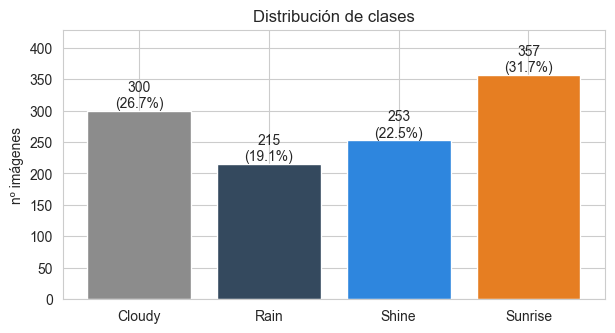

Ratio desbalanceo (máx/mín): 1.66
Exactitud de un clasificador "tonto" que siempre dice la clase mayoritaria: 31.7%


In [4]:
ok = meta[meta.ok].reset_index(drop=True)
cuenta = ok.clase.value_counts().reindex(CLASES)

fig, ax = plt.subplots(figsize=(7, 3.5))
barras = ax.bar(cuenta.index, cuenta.values, color=[COLORES[c] for c in cuenta.index])
for b, v in zip(barras, cuenta.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 5, f'{v}\n({v / cuenta.sum():.1%})', ha='center')
ax.set_ylabel('nº imágenes'); ax.set_title('Distribución de clases'); ax.set_ylim(0, cuenta.max() * 1.2)
plt.show()

print(f'Ratio desbalanceo (máx/mín): {cuenta.max() / cuenta.min():.2f}')
print(f'Exactitud de un clasificador "tonto" que siempre dice la clase mayoritaria: {cuenta.max() / cuenta.sum():.1%}')

**Qué vemos.** Las clases no están perfectamente equilibradas, pero tampoco hay un desequilibrio grave. Sunrise es la más numerosa (357 imágenes, un 31,7 %) y Rain la que menos (215, un 19,1 %), con Cloudy (300) y Shine (253) entre medias. La proporción entre la clase mayor y la menor es de 1,66.

Este número nos sirve de referencia: un clasificador que respondiera siempre «Sunrise» ya acertaría el **31,7 %**. Cualquier modelo que hagamos tiene que estar claramente por encima. Como Rain está algo infrarrepresentada, en la evaluación nos fijaremos en la F1-macro además de en la exactitud, y entrenaremos con `class_weight='balanced'` para que no salga perjudicada.

## 3. Dimensiones, proporción y peso de los archivos
Si el tamaño de la imagen dependiera de la clase, un modelo podría "hacer trampa" aprendiendo la resolución en vez del tiempo atmosférico (un atajo del dataset).

clase           Cloudy     Rain    Shine  Sunrise
ancho   count   300.00   215.00   253.00   357.00
        mean    416.08   633.00   423.98   564.16
        std     332.35   549.92   395.09   713.07
        min     183.00   183.00   158.00   190.00
        25%     246.50   286.50   245.00   255.00
        50%     274.50   553.00   281.00   283.00
        75%     381.25   742.00   318.00   480.00
        max    2000.00  4288.00  2880.00  4752.00
alto    count   300.00   215.00   253.00   357.00
        mean    277.50   411.19   284.11   372.72
        std     230.36   362.03   257.23   467.40
        min     134.00   158.00   111.00    94.00
        25%     167.00   184.00   168.00   168.00
        50%     178.00   352.00   177.00   181.00
        75%     300.00   473.00   226.00   338.00
        max    2000.00  2848.00  1800.00  3195.00
aspecto count   300.00   215.00   253.00   357.00
        mean      1.52     1.55     1.51     1.53
        std       0.28     0.24     0.29     0.31
        min       0.67     0.67     0.56     0.62
        25%       1.33     1.41     1.34     1.34
        50%       1.50     1.51     1.51     1.50
        75%       1.73     1.78     1.76     1.60
        max       2.36     2.22     2.70     3.19
mpx     count   300.00   215.00   253.00   357.00
        mean      0.19     0.45     0.22     0.54
        std       0.41     1.23     0.54     1.75
        min       0.03     0.04     0.02     0.03
        25%       0.04     0.05     0.04     0.04
        50%       0.05     0.19     0.05     0.05
        75%       0.09     0.32     0.06     0.16
        max       4.00    12.21     5.18    15.05
kb      count   300.00   215.00   253.00   357.00
        mean     25.37   150.59    39.80   125.00
        std      58.40   496.23   121.65   462.19
        min       2.31     4.77     2.05     2.09
        25%       4.33    10.12     5.62     4.94
        50%       5.47    36.32     7.41     6.71
        75%      12.77    73.15    10.63    27.83
        max     535.26  4124.71  1000.39  4279.08

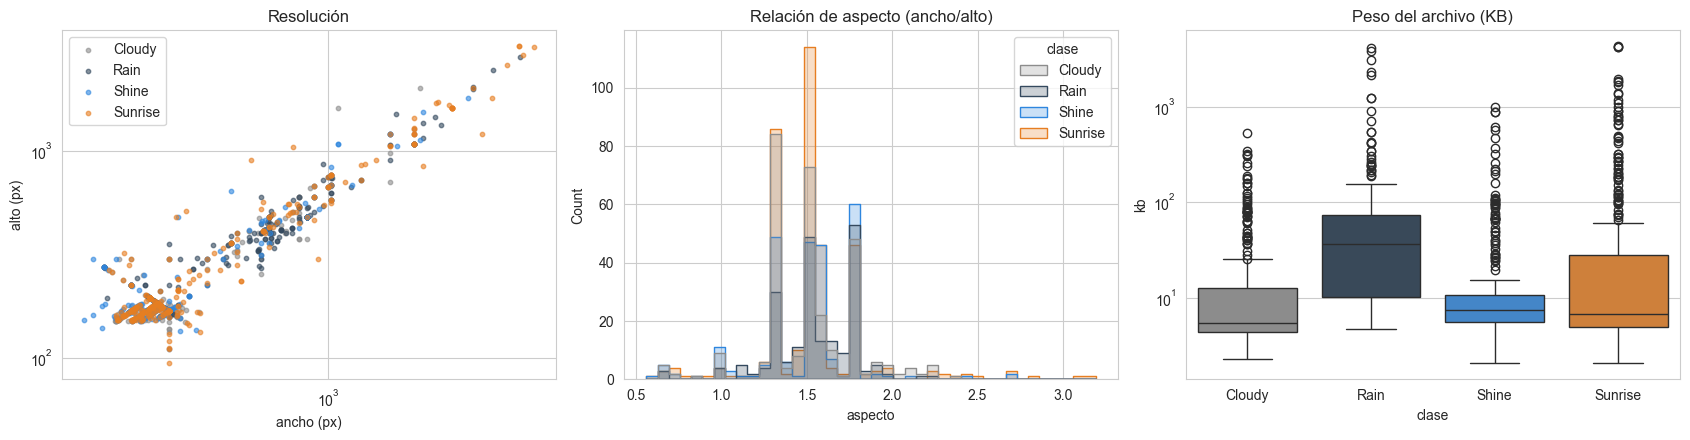

Resoluciones más frecuentes:


259x194      64
300x168      53
275x183      49
284x177      38
852x480      29
299x168      26
1920x1080    14
225x225      12
183x275       8
480x360       8
Name: count, dtype: int64

In [5]:
ok['aspecto'] = ok.ancho / ok.alto
ok['mpx'] = ok.ancho * ok.alto / 1e6

display(ok.groupby('clase')[['ancho', 'alto', 'aspecto', 'mpx', 'kb']].describe().T.round(2))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for clase in CLASES:
    s = ok[ok.clase == clase]
    axes[0].scatter(s.ancho, s.alto, s=10, alpha=.6, c=COLORES[clase], label=clase)
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel('ancho (px)'); axes[0].set_ylabel('alto (px)'); axes[0].legend(); axes[0].set_title('Resolución')

sns.histplot(data=ok, x='aspecto', hue='clase', palette=COLORES, element='step', bins=40, ax=axes[1])
axes[1].set_title('Relación de aspecto (ancho/alto)')
sns.boxplot(data=ok, x='clase', y='kb', hue='clase', palette=COLORES, order=CLASES, ax=axes[2], legend=False)
axes[2].set_yscale('log'); axes[2].set_title('Peso del archivo (KB)')
plt.tight_layout(); plt.show()

print('Resoluciones más frecuentes:')
display((ok.ancho.astype(str) + 'x' + ok.alto.astype(str)).value_counts().head(10))

**Qué vemos.** Las resoluciones son de lo más variadas: desde miniaturas de 158×111 píxeles hasta fotos de 4752×3195. Aun así, la mayoría son imágenes pequeñas sacadas de internet; las más repetidas son 259×194 (64 imágenes), 300×168 (53) y 275×183 (49).

Hay una clase que no sigue el patrón: **Rain**. Su mediana está en 553×352 píxeles, mientras que las otras tres rondan los 280×180. También son las imágenes que más pesan (36 KB de mediana frente a los 5-7 KB del resto). Todo apunta a que las fotos de lluvia se recopilaron de fuentes distintas a las demás.

La relación de aspecto, en cambio, es prácticamente la misma en todas las clases (en torno a 1,5, con picos en 4:3, 3:2 y 16:9), así que por ahí no hay nada que rascar.

In [6]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
for cols_meta in [['ancho', 'alto'], ['ancho', 'alto', 'aspecto'], ['ancho', 'alto', 'kb']]:
    acc = cross_val_score(DecisionTreeClassifier(max_depth=5, random_state=SEED), ok[cols_meta], ok.clase, cv=cv).mean()
    print(f'{str(cols_meta):30s} → exactitud {acc:.2%}   (azar mayoritario: {cuenta.max()/cuenta.sum():.2%})')

['ancho', 'alto']              → exactitud 33.51%   (azar mayoritario: 31.73%)
['ancho', 'alto', 'aspecto']   → exactitud 35.11%   (azar mayoritario: 31.73%)
['ancho', 'alto', 'kb']        → exactitud 41.07%   (azar mayoritario: 31.73%)


**Qué vemos.** Queríamos comprobar si un modelo podría «hacer trampa» fijándose en el tamaño de la imagen en lugar de en lo que sale en ella. Con solo el ancho y el alto, un árbol de decisión acierta un 33,5 %, prácticamente lo mismo que el clasificador que siempre dice la clase mayoritaria (31,7 %). Por la resolución, poco que temer.

Si le añadimos el peso del archivo, la cosa cambia: sube al 41,1 %, unos nueve puntos por encima del azar. Es un sesgo moderado y viene sobre todo de Rain, cuyas imágenes son más grandes y pesadas. Por eso redimensionamos todas las imágenes a un tamaño fijo y no usamos nunca ni el tamaño ni el peso como característica. Esto también nos protege de cara al reto, porque las fotos del móvil van a tener una resolución muy distinta a la del dataset.

## 4. Galería de ejemplos

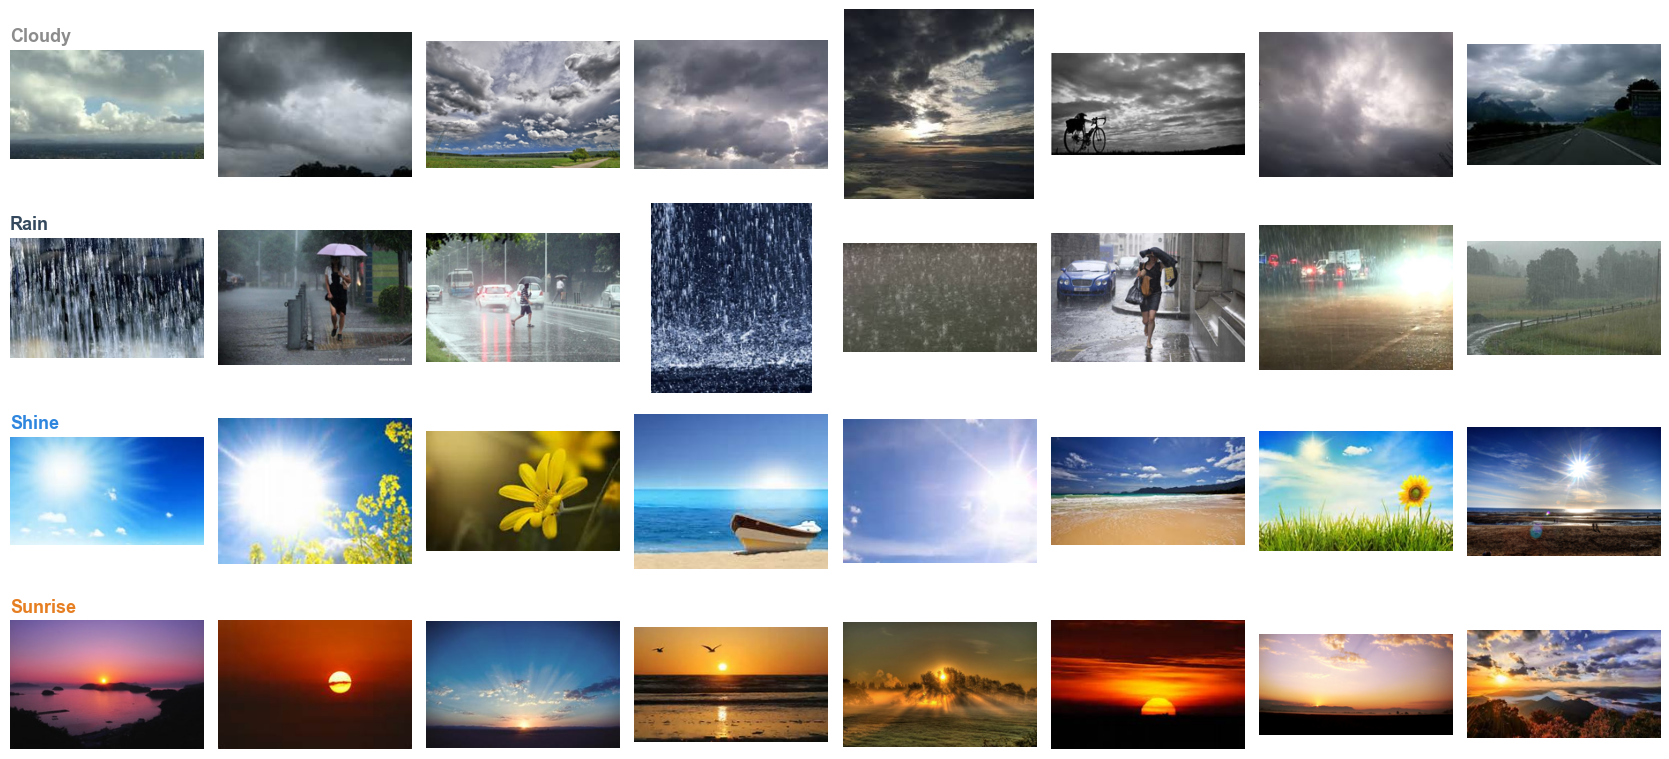

In [7]:
def vista(p, lado=220):
    """Carga una imagen en RGB conservando la proporción (para visualizar)."""
    with Image.open(p) as im:
        im = ImageOps.exif_transpose(im).convert('RGB')
        im.thumbnail((lado, lado))
        return np.asarray(im)

n = 8
fig, axes = plt.subplots(len(CLASES), n, figsize=(2.1 * n, 2 * len(CLASES)))
for f, clase in enumerate(CLASES):
    rutas = ok[ok.clase == clase].ruta.sample(n, random_state=SEED)
    for c, p in enumerate(rutas):
        axes[f, c].imshow(vista(p)); axes[f, c].axis('off')
    axes[f, 0].set_title(clase, loc='left', fontsize=13, fontweight='bold', color=COLORES[clase])
plt.tight_layout(); plt.show()

**Qué vemos.** Mirar las fotos ayuda a entender qué significa cada clase en la práctica.

En **Cloudy** el protagonista es el cielo, normalmente con nubes de tormenta, aunque a veces asoman huecos de azul. Algunas están en blanco y negro. **Rain** es la clase más variada: hay calles con gente y paraguas, coches con los faros encendidos, primeros planos de gotas y paisajes con niebla. Aquí el cielo casi nunca es lo importante; la lluvia se nota en la textura (trazos, gotas, reflejos), no en el color.

**Shine** es cielo azul intenso con el sol visible, playas y vegetación, aunque se cuela alguna imagen discutible, como una flor amarilla en primer plano que poco tiene que ver con el tiempo. Y **Sunrise** mezcla amaneceres y atardeceres sin distinguirlos, casi siempre con naranjas y rojos, el sol cerca del horizonte y el suelo en silueta.

Ya desde aquí se intuyen las confusiones que veremos más adelante: un día nublado con claros se parece bastante a uno soleado, y un nublado oscuro se parece a uno de lluvia.

## 5. Carga en memoria a tamaño fijo
Todas las imágenes a 128×128 en RGB. Para estadísticas de color la deformación por cambiar la proporción no importa, y así todas las imágenes pesan lo mismo en el análisis.

In [8]:
LADO = 128

def cargar(p, lado=LADO):
    with Image.open(p) as im:
        im = ImageOps.exif_transpose(im).convert('RGB').resize((lado, lado), Image.Resampling.BILINEAR)
    return np.asarray(im)

X = np.stack([cargar(p) for p in tqdm(ok.ruta)])
y = np.asarray(ok.clase, dtype=str)
print('X:', X.shape, X.dtype, f'· {X.nbytes / 1e6:.0f} MB')

# Imágenes en RGB pero que son realmente en blanco y negro (R≈G≈B)
dif_canales = np.abs(X.astype(np.int16) - X.mean(-1, keepdims=True)).mean(axis=(1, 2, 3))
ok['casi_gris'] = dif_canales < 2
print('\nImágenes prácticamente en escala de grises por clase:')
display(ok.groupby('clase').casi_gris.sum())

100%|██████████| 1125/1125 [00:03<00:00, 312.85it/s]


X: (1125, 128, 128, 3) uint8 · 55 MB

Imágenes prácticamente en escala de grises por clase:


clase
Cloudy     32
Rain       39
Shine       0
Sunrise     0
Name: casi_gris, dtype: int64

**Qué vemos.** Las 1125 imágenes caben sin problema en memoria a 128×128 (unos 55 MB) y se cargan en un par de segundos.

El dato interesante es el de las imágenes que, aunque estén guardadas en RGB, son en realidad fotos en blanco y negro: hay **71**, de las cuales 32 son de Cloudy, 39 de Rain y ninguna de Shine ni de Sunrise. Es decir, casi una de cada cinco fotos de lluvia no tiene color. Esto es un sesgo del propio dataset, y el modelo podría acabar aprendiendo que «sin color» equivale a «nublado o lluvia». Tiene cierta lógica (un cielo cubierto tiene poco color), pero una foto en blanco y negro de un día soleado lo engañaría. Para estas imágenes, lo único que nos queda es el brillo y la textura.

## 6. Duplicados y casi-duplicados
Si la misma foto (o una copia redimensionada o con otra compresión) aparece a la vez en entrenamiento y en test, el modelo «se sabe» la respuesta y la exactitud sale inflada. Para detectarlo, a cada imagen le calculamos una firma con dos partes:
- **Estructura:** un hash perceptual de diferencias (dHash) de 16×16, es decir, 256 bits que indican si cada píxel es más claro o más oscuro que el de su derecha.
- **Color:** una miniatura de 8×8 en RGB.

Dos imágenes las consideramos casi duplicadas solo si se parecen **en las dos cosas a la vez**. En una primera versión usamos únicamente un dHash de 8×8 en gris y daba muchos falsos positivos: cualquier foto con un sol en el centro tenía el mismo hash, fuera un mediodía azul o un atardecer rojo.

100%|██████████| 1125/1125 [00:03<00:00, 301.96it/s]


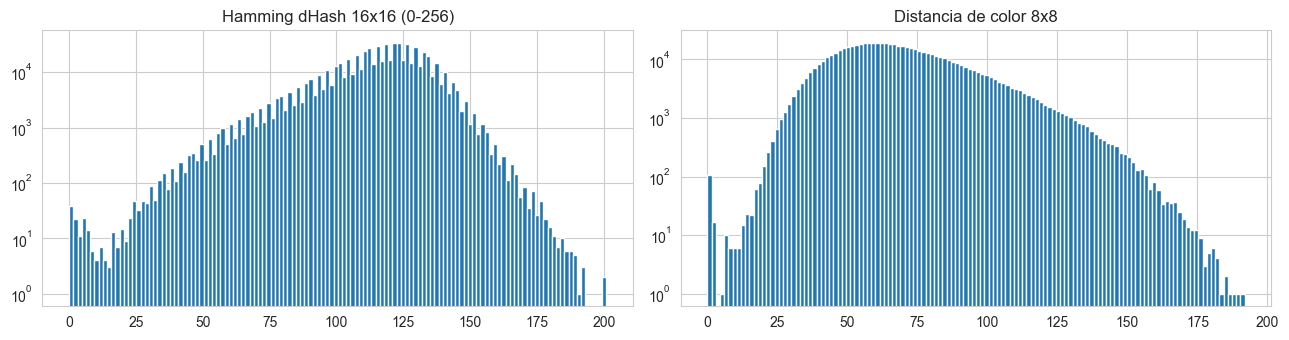

Casi-duplicados (Hamming ≤ 20/256 y color ≤ 12): 121
  · misma clase   : 121
  · DISTINTA clase: 0


In [30]:
# Firma de cada imagen: dHash 16x16 (estructura) + miniatura 8x8 en color
def firma(p, n=16):
    with Image.open(p) as im:
        im = ImageOps.exif_transpose(im).convert('RGB')
        g = np.asarray(im.convert('L').resize((n + 1, n), Image.Resampling.LANCZOS), dtype=np.int16)
        c = np.asarray(im.resize((8, 8), Image.Resampling.BOX), dtype=np.float32).ravel()
    return (g[:, 1:] > g[:, :-1]).ravel(), c

firmas = [firma(p) for p in tqdm(ok.ruta)]
Hh = np.array([f[0] for f in firmas], dtype=np.float32)   # (N, 256)
CS = np.array([f[1] for f in firmas])                      # (N, 192)

# Distancia de Hamming entre todos los pares con productos de matrices (sin reventar la memoria)
D = Hh @ (1 - Hh).T + (1 - Hh) @ Hh.T
# Distancia de color: diferencia media por píxel y canal (0-255)
from scipy.spatial.distance import cdist
DC = cdist(CS, CS, 'cityblock') / CS.shape[1]

iu = np.triu_indices(len(ok), 1)
pares = pd.DataFrame({'i': iu[0], 'j': iu[1], 'dist': D[iu].astype(int), 'dcolor': DC[iu]})

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].hist(pares.dist, bins=128, log=True); axes[0].set_title('Hamming dHash 16x16 (0-256)')
axes[1].hist(pares.dcolor, bins=128, log=True); axes[1].set_title('Distancia de color 8x8')
plt.tight_layout(); plt.show()

UMBRAL_H, UMBRAL_C = 20, 12
cand = pares[(pares.dist <= UMBRAL_H) & (pares.dcolor <= UMBRAL_C)].copy()
cand['clase_i'], cand['clase_j'] = y[cand.i], y[cand.j]
cand['misma_clase'] = cand.clase_i == cand.clase_j
print(f'Casi-duplicados (Hamming ≤ {UMBRAL_H}/256 y color ≤ {UMBRAL_C}): {len(cand)}')
print('  · misma clase   :', cand.misma_clase.sum())
print('  · DISTINTA clase:', (~cand.misma_clase).sum())

**Qué vemos.** Los dos histogramas se parecen mucho y cuentan lo mismo. Casi todos los pares de imágenes forman una gran campana (en torno a 120 de 256 bits de diferencia en estructura y unos 60 niveles de diferencia en color), que corresponde a imágenes que no tienen nada que ver entre sí. Pero pegado al cero aparece un pequeño grupo de pares, separado del resto, y esos son los duplicados de verdad. Lo que buscamos son umbrales que caigan en el hueco entre ambos grupos, y con 20 bits de estructura y 12 niveles de color quedamos en esa zona.

Con este criterio encontramos **121 pares de casi-duplicados, todos dentro de la misma clase**. No hay ninguno entre clases distintas, así que el dataset no tiene etiquetas contradictorias: los 492 pares «sospechosos» que nos salían con el método anterior eran falsos positivos. Estos 121 pares incluyen también las copias exactas byte a byte (por ejemplo, el trío `rain28`, `rain29` y `rain96`), porque una copia idéntica tiene distancia cero en estructura y en color.

Casi-duplicados entre clases DISTINTAS:
Ninguno
Casi-duplicados dentro de la misma clase:


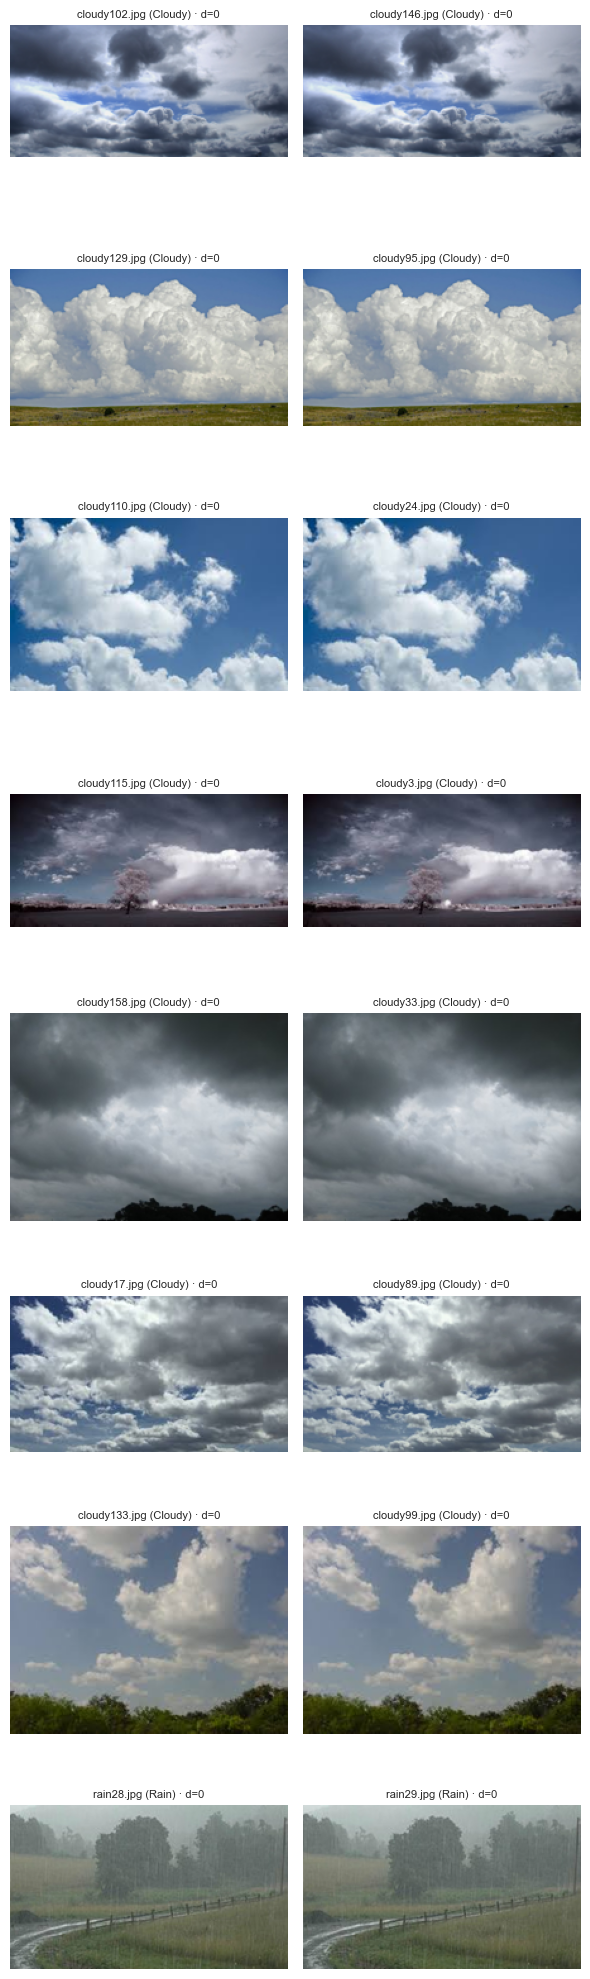

In [31]:
def ver_pares(df, n=8):
    df = df.sort_values('dist').head(n)
    if df.empty:
        print('Ninguno'); return
    fig, axes = plt.subplots(len(df), 2, figsize=(6, 2.6 * len(df)))
    axes = np.atleast_2d(axes)
    for f, r in enumerate(df.itertuples()):
        for c, i in enumerate([r.i, r.j]):
            axes[f, c].imshow(vista(ok.ruta[i])); axes[f, c].axis('off')
            axes[f, c].set_title(f'{ok.archivo[i]} ({y[i]}) · d={r.dist}', fontsize=8)
    plt.tight_layout(); plt.show()

print('Casi-duplicados entre clases DISTINTAS:'); ver_pares(cand[~cand.misma_clase])
print('Casi-duplicados dentro de la misma clase:'); ver_pares(cand[cand.misma_clase])

**Qué vemos.** Como no hay pares entre clases distintas, la primera parte de la celda simplemente dice «Ninguno».

Los pares dentro de la misma clase son, sin discusión, la misma foto: `cloudy102` y `cloudy146`, `cloudy129` y `cloudy95`, `cloudy110` y `cloudy24`, `cloudy115` y `cloudy3`, `cloudy158` y `cloudy33`… Todos tienen distancia 0, y a simple vista no hay ninguna diferencia entre una imagen y su pareja. La mayoría son de Cloudy, lo que hace pensar que una parte de esa clase se descargó dos veces con distinto nombre. También aparecen en otras clases, como `rain28` y `rain29`.

No es un problema grave para el análisis exploratorio, porque una imagen repetida apenas mueve las medias de su clase. Sí lo es para evaluar el modelo, y por eso en el siguiente paso agrupamos los duplicados.

In [32]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

adj = coo_matrix((np.ones(len(cand)), (cand.i, cand.j)), shape=(len(ok), len(ok)))
_, grupo_dup = connected_components(adj, directed=False)
ok['grupo_dup'] = grupo_dup
print('Imágenes:', len(ok), '· grupos únicos:', len(np.unique(grupo_dup)))

Imágenes: 1125 · grupos únicos: 1015


**Qué vemos.** Al unir cada imagen con sus duplicados, las 1125 imágenes quedan en **1015 grupos**. Es decir, unas 110 imágenes son copias de otras que ya están en el dataset (casi un 10 %), y en la práctica el dataset tiene algo más de mil fotos distintas.

Estos grupos los usamos en la validación cruzada de la sección 16 con `StratifiedGroupKFold`, que obliga a que una foto y todas sus copias vayan siempre al mismo fold. Así nos aseguramos de que el modelo nunca se evalúa con una imagen que ya ha visto durante el entrenamiento. Si en el modelo final preferimos eliminar las copias en vez de agruparlas, basta con quedarse con una imagen de cada grupo.

## 7. Estructura espacial: imagen media y perfil vertical
Las fotos de cielo tienen una estructura típica: cielo arriba y suelo/horizonte abajo. La imagen media por clase lo resume.

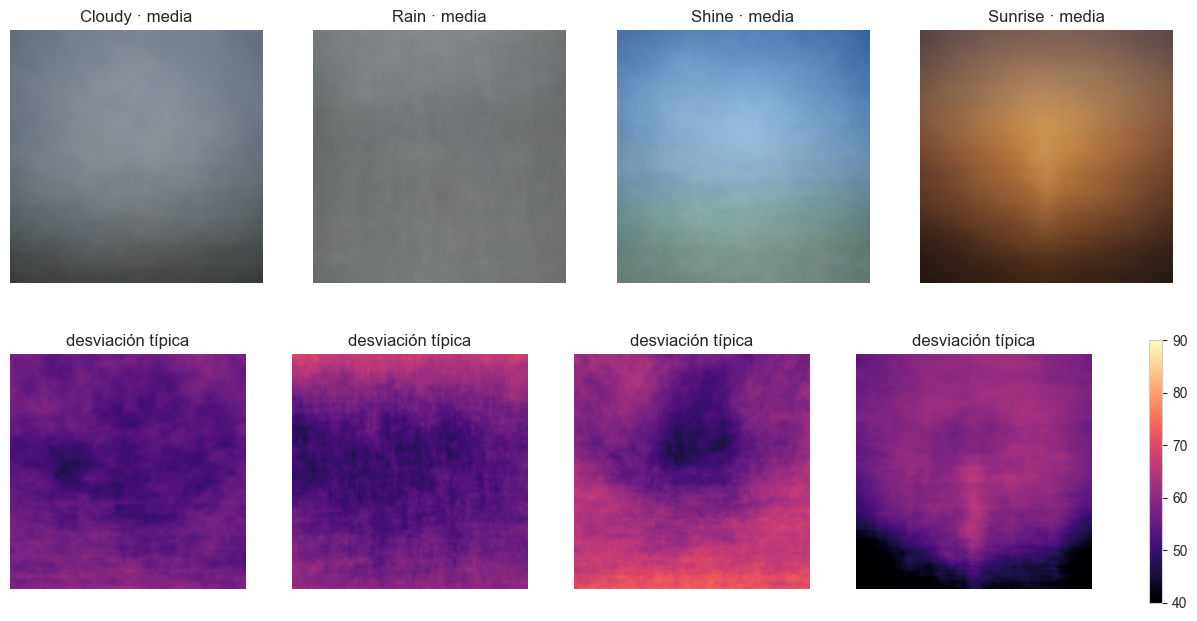

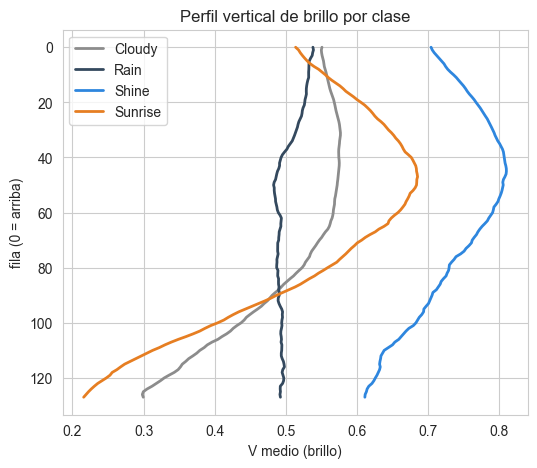

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7.5))
for k, clase in enumerate(CLASES):
    Xi = X[y == clase].astype(np.float32)
    axes[0, k].imshow(Xi.mean(0).astype(np.uint8)); axes[0, k].set_title(f'{clase} · media')
    m = axes[1, k].imshow(Xi.std(0).mean(-1), cmap='magma', vmin=40, vmax=90)
    axes[1, k].set_title('desviación típica')
    for a in axes[:, k]: a.axis('off')
plt.colorbar(m, ax=axes[1, :], fraction=0.02); plt.show()

# Perfil vertical de brillo (V = max(R,G,B))
V_all = X.max(-1) / 255
fig, ax = plt.subplots(figsize=(6, 5))
for clase in CLASES:
    perfil = V_all[y == clase].mean(axis=(0, 2))
    ax.plot(perfil, np.arange(LADO), color=COLORES[clase], label=clase, lw=2)
ax.invert_yaxis(); ax.set_xlabel('V medio (brillo)'); ax.set_ylabel('fila (0 = arriba)')
ax.set_title('Perfil vertical de brillo por clase'); ax.legend(); plt.show()

**Qué vemos.** Promediar todas las imágenes de cada clase da un resultado muy expresivo.

La imagen media de **Cloudy** es un gris azulado con la franja de abajo más oscura, que es el suelo bajo un cielo cubierto. La de **Rain** es un gris uniforme sin estructura vertical: como las fotos de lluvia suelen estar hechas a pie de calle, no hay una separación clara entre cielo y suelo. **Shine** es azul arriba y verdosa o turquesa abajo (vegetación, mar, playa). Y **Sunrise** es la más reconocible: un foco naranja en el centro, el sol cerca del horizonte, rodeado de bordes casi negros.

Los mapas de desviación típica cuentan cosas complementarias. En Sunrise, la parte de abajo apenas varía porque casi siempre es una silueta negra. En Shine pasa lo contrario: el suelo cambia mucho de una foto a otra, mientras que el cielo azul del centro es bastante constante.

El perfil vertical de brillo lo resume muy bien. **Rain** es casi una línea recta (el brillo va de 0,49 a 0,53 de arriba abajo). **Cloudy** se va oscureciendo poco a poco, de 0,55 a 0,30. **Shine** es la más luminosa en todas las alturas, con un máximo de 0,81. Y **Sunrise** tiene la forma más marcada: sube hasta 0,68 donde está el sol y cae hasta 0,22 en el suelo. Todo esto nos dice que la posición importa, y que merece la pena calcular algunas características por separado para la mitad superior y la inferior de la imagen.

## 8. Extracción de características para el EDA
Por cada imagen calculamos:
- **Histogramas** (32 bins) de R, G, B, H, S, V, L\*, a\*, b\* y LBP.
- **Momentos** (media, varianza, sesgo, curtosis) de cada canal. **El tono H es circular** (0 y 1 son el mismo rojo), así que en vez de su media lineal usamos la media circular ponderada por la saturación: en píxeles grises el tono no significa nada.
- **Entropía**: global y local (disco r=5; media, desviación y percentil 90).
- **Extra**: proporción de píxeles azul cielo / cálidos / oscuros / quemados / grises, diferencia de brillo arriba-abajo, *colorfulness* (Hasler-Süsstrunk), *dark channel* (indicador de bruma/neblina), contraste RMS, densidad de bordes y Haralick (GLCM).

In [13]:
def momentos(x, eps=1e-12):
    x = x.astype(np.float64).ravel()
    mu, var = x.mean(), x.var()
    if var < eps:                       # canal plano (p. ej. S en una imagen gris)
        return mu, var, 0.0, 0.0
    z = x - mu
    return mu, var, (z ** 3).mean() / var ** 1.5, (z ** 4).mean() / var ** 2

def chi2(h, g, eps=1e-10):
    return 0.5 * np.sum((h - g) ** 2 / (h + g + eps))

def haralick(P):
    Ng = P.shape[0]
    i, j = np.meshgrid(np.arange(Ng), np.arange(Ng), indexing='ij')
    contraste = np.sum((i - j) ** 2 * P)
    homogeneidad = np.sum(P / (1 + (i - j) ** 2))
    nz = P[P > 0]
    entropia = -np.sum(nz * np.log2(nz))
    mu_i, mu_j = np.sum(i * P), np.sum(j * P)
    s_i = np.sqrt(np.sum((i - mu_i) ** 2 * P)); s_j = np.sqrt(np.sum((j - mu_j) ** 2 * P))
    correlacion = np.sum((i - mu_i) * (j - mu_j) * P) / (s_i * s_j + 1e-12)
    return dict(contraste=contraste, homogeneidad=homogeneidad, entropia=entropia, correlacion=correlacion)

def glcm_feats(gris_u8, niveles=32, d=1):
    q = (gris_u8.astype(int) * niveles // 256).astype(np.uint8)
    G = feature.graycomatrix(q, [d], [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4], levels=niveles, symmetric=True, normed=True)
    return haralick(G[:, :, 0, :].mean(axis=2))

BINS = 32
RANGOS = {'R': (0, 1), 'G': (0, 1), 'B': (0, 1), 'H': (0, 1), 'S': (0, 1), 'V': (0, 1),
          'L': (0, 100), 'a': (-80, 80), 'b': (-80, 80)}

def canales(im):
    rgb = im.astype(np.float32) / 255
    hsv, lab = color.rgb2hsv(rgb), color.rgb2lab(rgb)
    return {'R': rgb[..., 0], 'G': rgb[..., 1], 'B': rgb[..., 2],
            'H': hsv[..., 0], 'S': hsv[..., 1], 'V': hsv[..., 2],
            'L': lab[..., 0], 'a': lab[..., 1], 'b': lab[..., 2]}

def colorfulness(im):
    R, G, B = [im[..., k].astype(float) for k in range(3)]
    rg, yb = R - G, 0.5 * (R + G) - B
    return np.hypot(rg.std(), yb.std()) + 0.3 * np.hypot(rg.mean(), yb.mean())

def dark_channel(im, k=15):
    return cv2.erode(im.min(axis=2), np.ones((k, k), np.uint8))

def extraer(im):
    ch = canales(im)
    f, h = {}, {}
    for c, v in ch.items():
        h[c] = np.histogram(v, bins=BINS, range=RANGOS[c])[0] / v.size
        if c != 'H':
            f[f'{c}_media'], f[f'{c}_var'], f[f'{c}_sesgo'], f[f'{c}_curt'] = momentos(v)

    # Tono circular ponderado por saturación
    H, S, V = ch['H'], ch['S'], ch['V']
    ang, w = 2 * np.pi * H, S + 1e-8
    cx, sy = (w * np.cos(ang)).sum() / w.sum(), (w * np.sin(ang)).sum() / w.sum()
    f['H_media_circ'] = (np.arctan2(sy, cx) / (2 * np.pi)) % 1
    f['H_concentr'] = np.hypot(cx, sy)          # 1 = un solo tono dominante, 0 = tonos dispersos
    h['H_pond'] = np.histogram(H, bins=BINS, range=(0, 1), weights=w)[0] / w.sum()

    # Proporciones de píxeles "semánticos"
    f['p_azul'] = np.mean((H > 0.5) & (H < 0.7) & (S > 0.25) & (V > 0.3))
    f['p_calido'] = np.mean(((H < 0.11) | (H > 0.95)) & (S > 0.3) & (V > 0.3))
    f['p_oscuro'] = np.mean(V < 0.2)
    f['p_quemado'] = np.mean(V > 0.95)
    f['p_gris'] = np.mean(S < 0.1)

    mitad = V.shape[0] // 2
    f['V_arriba'], f['V_abajo'] = V[:mitad].mean(), V[mitad:].mean()
    f['V_dif_vert'] = f['V_arriba'] - f['V_abajo']
    f['colorfulness'] = colorfulness(im)
    f['dark_channel'] = dark_channel(im).mean() / 255

    gris = util.img_as_ubyte(color.rgb2gray(im))
    f['contraste_rms'] = gris.std() / 255
    f['entropia_global'] = shannon_entropy(gris)
    ent = rank_entropy(gris, morphology.disk(5))
    f['entloc_media'], f['entloc_std'], f['entloc_p90'] = ent.mean(), ent.std(), np.percentile(ent, 90)
    f['bordes'] = feature.canny(gris, sigma=2).mean()
    for k, v in glcm_feats(gris).items():
        f[f'glcm_{k}'] = v
    lbp = feature.local_binary_pattern(gris, 8, 1, method='uniform')
    h['LBP'] = np.histogram(lbp, bins=np.arange(11))[0] / lbp.size
    return f, h

Aquí definimos las funciones de extracción. Algunas las reutilizamos del notebook de clase (momentos, distancia χ², Haralick a partir de la GLCM) y otras las añadimos pensando en este problema concreto: el tono tratado como variable circular y ponderado por la saturación, la proporción de píxeles azules, cálidos, grises, oscuros o quemados, la *colorfulness*, el *dark channel* (que da una idea de cuánta bruma hay), la entropía global y local, la densidad de bordes y el histograma LBP.

In [14]:
F, HISTS = [], {}
for im in tqdm(X):
    f, h = extraer(im)
    F.append(f)
    for k, v in h.items():
        HISTS.setdefault(k, []).append(v)

feats = pd.DataFrame(F)
feats.insert(0, 'clase', y)
HISTS = {k: np.array(v) for k, v in HISTS.items()}
cols = feats.columns.drop('clase')

print(feats.shape, '·', len(cols), 'características escalares')
print('NaN:', feats[cols].isna().sum().sum(), '· Inf:', np.isinf(feats[cols].values).sum())
feats.to_csv('features_eda.csv', index=False)     # por si quieres reutilizarlas
display(feats.head())

100%|██████████| 1125/1125 [00:23<00:00, 47.13it/s]


(1125, 55) · 54 características escalares
NaN: 0 · Inf: 0


,clase,R_media,R_var,R_sesgo,R_curt,G_media,G_var,G_sesgo,G_curt,B_media,...,contraste_rms,entropia_global,entloc_media,entloc_std,entloc_p90,bordes,glcm_contraste,glcm_homogeneidad,glcm_entropia,glcm_correlacion
0,Cloudy,0.403,0.044,0.565,2.606,0.403,0.044,0.565,2.606,0.403,...,0.209,7.600,4.305,0.971,5.444,0.053,0.889,0.783,6.171,0.990
1,Cloudy,0.558,0.033,-1.132,4.598,0.620,0.033,-1.531,5.782,0.722,...,0.183,7.183,4.660,0.714,5.507,0.066,1.640,0.715,6.213,0.976
2,Cloudy,0.554,0.020,0.040,2.850,0.554,0.022,-0.271,2.974,0.508,...,0.151,7.231,4.764,0.663,5.385,0.069,2.426,0.639,6.630,0.948
3,Cloudy,0.548,0.064,-0.449,1.882,0.563,0.063,-0.802,2.321,0.624,...,0.253,7.513,4.731,0.614,5.464,0.069,1.765,0.697,6.618,0.986
4,Cloudy,0.494,0.037,0.091,1.986,0.539,0.035,-0.018,2.019,0.624,...,0.188,7.500,5.025,0.631,5.677,0.096,2.115,0.644,6.876,0.971


**Qué vemos.** Obtenemos 54 características numéricas por imagen, sin ningún NaN ni infinito. La protección que pusimos en `momentos()` para los canales planos (por ejemplo, la saturación de una foto en blanco y negro) hace su trabajo.

En las primeras filas ya se nota el efecto de las imágenes grises: la primera foto de Cloudy tiene exactamente los mismos momentos en R, G y B (media 0,403, sesgo 0,565…), porque los tres canales son iguales. Para ese tipo de imágenes, el color no aporta nada.

El cálculo tarda unos 40 segundos, y lo que más cuesta es la entropía local. Conviene tenerlo en cuenta si más adelante queremos trabajar con imágenes más grandes.

## 9. Histogramas medios por clase en cada espacio de color
La línea es el histograma medio de la clase y la banda es ±1 desviación típica.

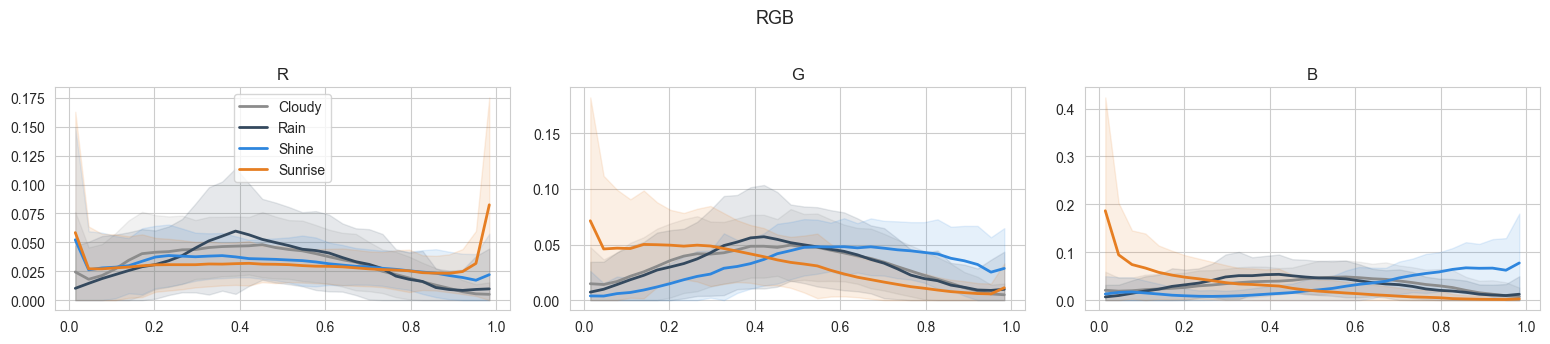

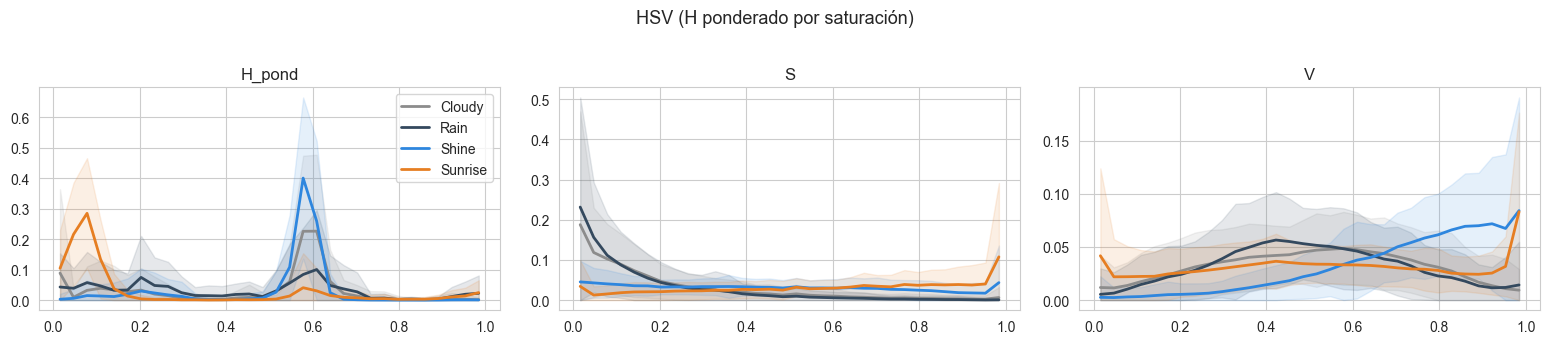

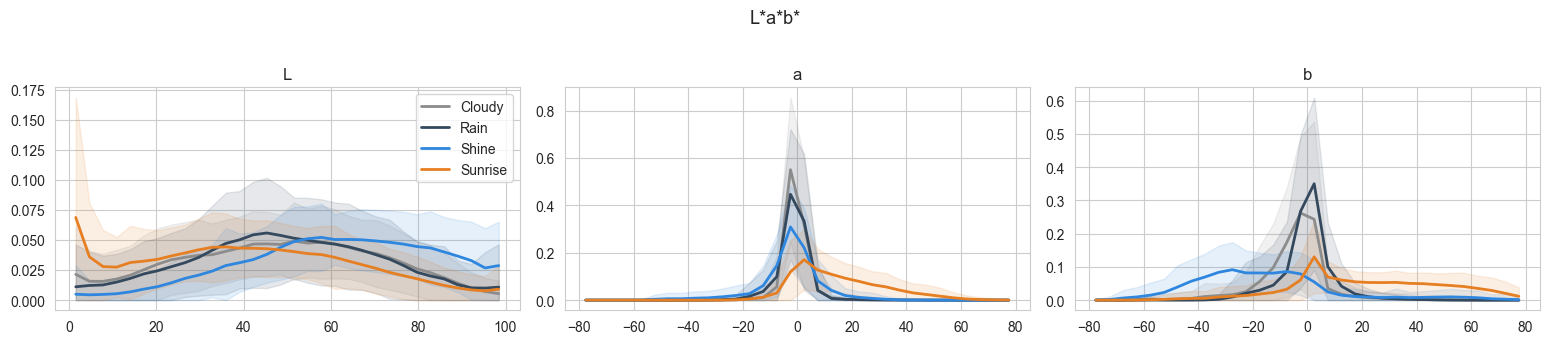

In [15]:
def plot_hists(lista, titulo):
    fig, axes = plt.subplots(1, len(lista), figsize=(5.2 * len(lista), 3.3))
    for ax, c in zip(axes, lista):
        lo, hi = RANGOS.get(c, (0, 1))
        xs = lo + (np.arange(BINS) + 0.5) * (hi - lo) / BINS
        for clase in CLASES:
            Hc = HISTS[c][y == clase]
            m, s = Hc.mean(0), Hc.std(0)
            ax.plot(xs, m, color=COLORES[clase], lw=2, label=clase)
            ax.fill_between(xs, np.clip(m - s, 0, None), m + s, color=COLORES[clase], alpha=0.12)
        ax.set_title(c)
    axes[0].legend(); plt.suptitle(titulo, y=1.03, fontsize=13); plt.tight_layout(); plt.show()

plot_hists(['R', 'G', 'B'], 'RGB')
plot_hists(['H_pond', 'S', 'V'], 'HSV (H ponderado por saturación)')
plot_hists(['L', 'a', 'b'], 'L*a*b*')

**Qué vemos.** Comparar los tres espacios de color deja bastante clara la ventaja de separar el color del brillo.

En **RGB**, Cloudy y Rain son prácticamente indistinguibles: las dos tienen una campana centrada en torno a 0,4 en los tres canales. Shine desplaza el canal azul hacia valores altos, y Sunrise acumula muchos píxeles en 0 en verde y azul (las siluetas oscuras) y un pico en 1 en el rojo.

En **HSV**, el tono es el canal que más dice. Shine tiene un pico muy estrecho en torno a 0,58 (unos 210°, el azul del cielo); Sunrise lo tiene entre 0,05 y 0,10 (los naranjas); Cloudy tiene un pequeño pico en el azul, que corresponde a los claros entre nubes; y Rain tiene el tono más repartido de todos. La saturación agrupa a Cloudy y Rain cerca de 0 (colores apagados), mientras que Sunrise tiene una cola hacia 1. En el brillo, Shine tira hacia los valores altos y Sunrise es bimodal: negro en las siluetas y blanco en el sol.

En **L\*a\*b\***, el canal b\* separa limpiamente las clases: Shine en negativo (azul), Sunrise en positivo (amarillo-naranja) y Cloudy y Rain en un pico estrecho en cero. El canal a\* solo destaca para Sunrise, y L\* se comporta igual que V y apenas discrimina.

La conclusión es la que esperábamos por la teoría: HSV y Lab funcionan mejor que RGB. Lo que ningún espacio de color consigue es distinguir Cloudy de Rain.

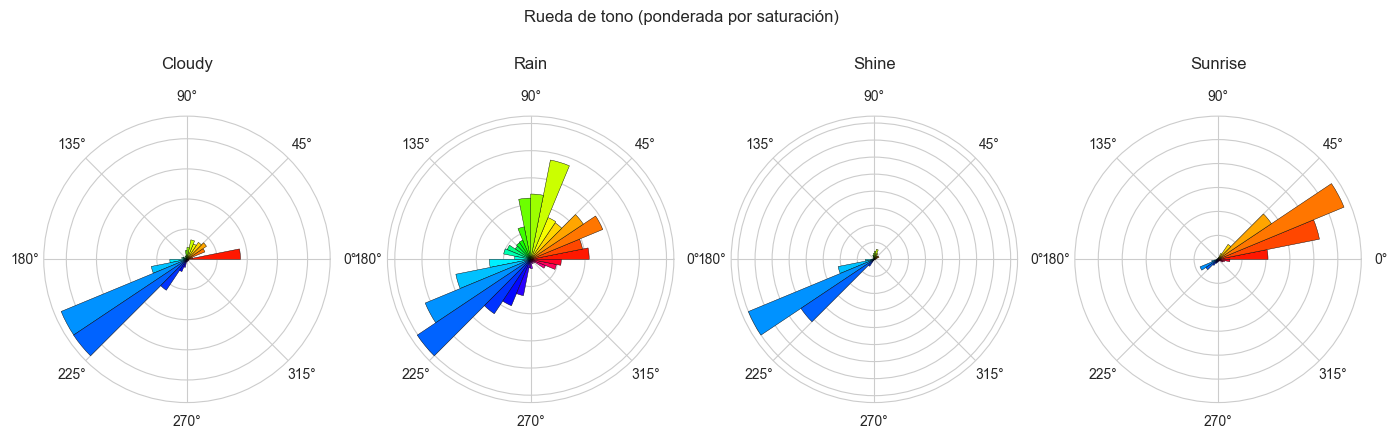

In [16]:
theta = 2 * np.pi * (np.arange(BINS) + 0.5) / BINS
col_bins = plt.cm.hsv((np.arange(BINS) + 0.5) / BINS)
fig, axes = plt.subplots(1, 4, subplot_kw={'projection': 'polar'}, figsize=(17, 4.5))
for ax, clase in zip(axes, CLASES):
    m = HISTS['H_pond'][y == clase].mean(0)
    ax.bar(theta, m, width=2 * np.pi / BINS, color=col_bins, edgecolor='k', linewidth=.3)
    ax.set_title(clase, pad=15); ax.set_yticklabels([])
plt.suptitle('Rueda de tono (ponderada por saturación)', y=1.05); plt.show()

**Qué vemos.** La rueda de tono es probablemente la forma más intuitiva de ver cómo es cada clase.

En **Shine** prácticamente todo el tono se concentra en un único sector azul, entre 200° y 225°. **Sunrise** ocupa justo el lado opuesto de la rueda, entre los rojos y los naranjas (10°-40°). **Cloudy** también apunta al azul, por los claros entre nubes, pero con mucha menos fuerza, porque al ponderar por la saturación los grises cuentan muy poco.

**Rain** es la única clase con el tono repartido por toda la rueda: azules, verdes y amarillos de la vegetación, naranjas de los faros y las farolas… Las fotos de lluvia no se definen por el color del cielo, sino por la escena en la que llueve.

Este gráfico también justifica que tratemos el tono como una variable circular. Si hiciéramos la media de H de forma lineal, un rojo de 5° y otro de 355° nos saldrían como colores opuestos, cuando en realidad son casi el mismo.

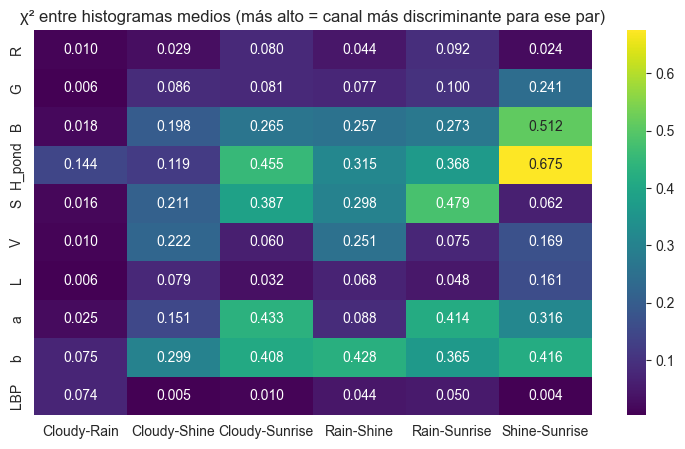

In [17]:
lista = ['R', 'G', 'B', 'H_pond', 'S', 'V', 'L', 'a', 'b', 'LBP']
tabla_chi = pd.DataFrame({f'{a}-{b}': {c: chi2(HISTS[c][y == a].mean(0), HISTS[c][y == b].mean(0)) for c in lista}
                          for a, b in combinations(CLASES, 2)})
plt.figure(figsize=(9, 5))
sns.heatmap(tabla_chi, annot=True, fmt='.3f', cmap='viridis')
plt.title('χ² entre histogramas medios (más alto = canal más discriminante para ese par)')
plt.show()

**Qué vemos.** Esta tabla nos dice qué canal separa mejor cada pareja de clases.

La pareja más fácil es **Shine contra Sunrise**, sobre todo gracias al tono (χ² = 0,675) y al canal azul (0,512), cosa lógica teniendo en cuenta que están en lados opuestos de la rueda de color. En las parejas donde aparece Sunrise destacan el tono, a\*, b\* y la saturación; en las que aparece Shine, sobre todo b\* y el brillo.

La pareja difícil es **Cloudy contra Rain**: todos sus valores son bajos. Lo interesante es cuáles son los más altos: el tono (0,144), b\* (0,075) y el **LBP (0,074)**. El LBP, que es un descriptor de textura, no sirve para separar ninguna otra pareja (siempre por debajo de 0,05), pero aquí sí aparece. Es la primera pista de que **lo que distingue la lluvia de un cielo nublado es la textura, no el color**.

En general, R, G y L\* son los canales que menos ayudan.

## 10. Distribución de las características escalares por clase

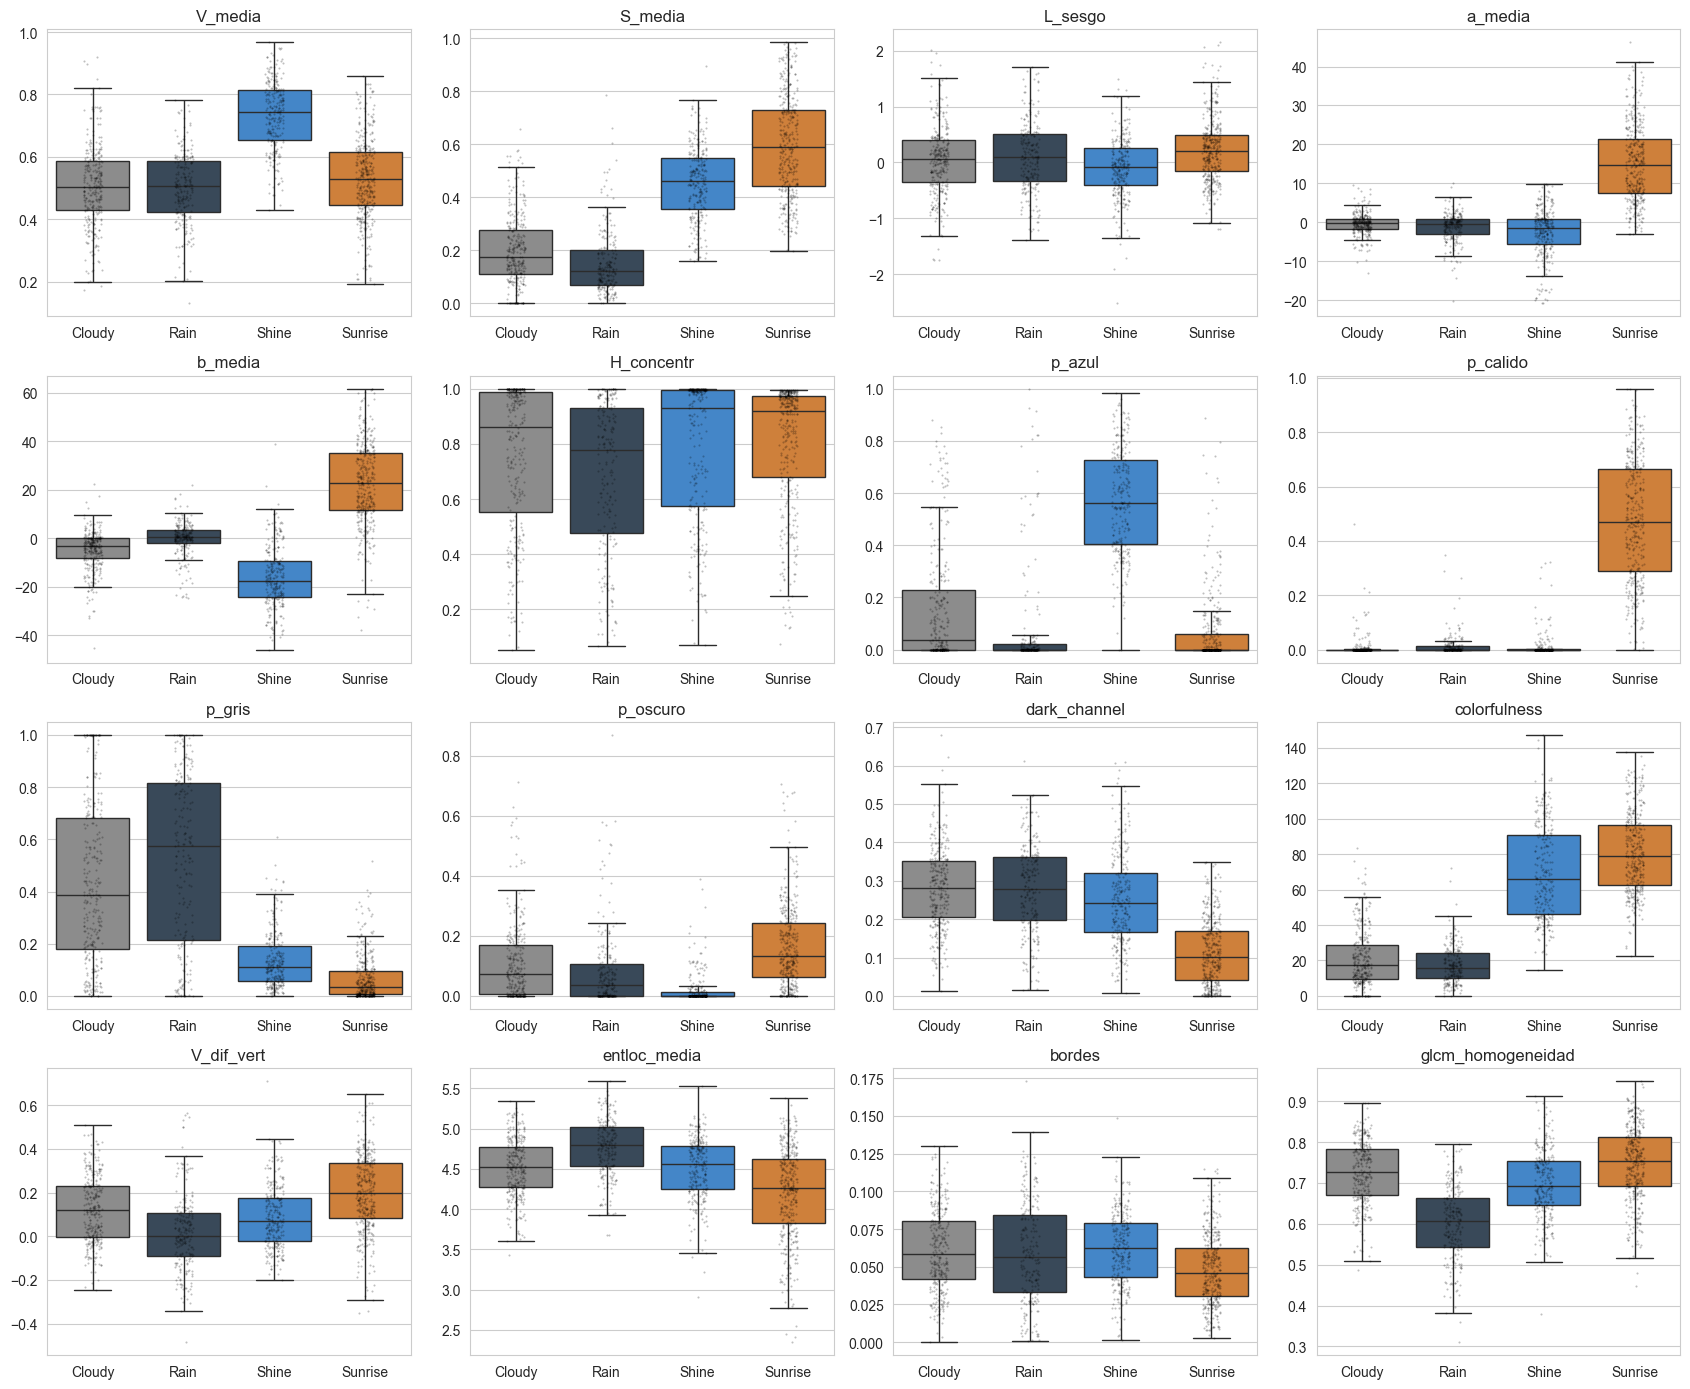

Mediana por clase:


clase,Cloudy,Rain,Shine,Sunrise
V_media,0.503684,0.506439,0.743794,0.528567
S_media,0.175068,0.122641,0.462082,0.587595
L_sesgo,0.067624,0.091889,-0.073238,0.207134
a_media,-0.180421,-0.438580,-1.426815,14.716434
b_media,-3.115095,0.590463,-17.459352,22.845462
H_concentr,0.861600,0.778731,0.930106,0.917921
p_azul,0.038055,0.000183,0.562561,0.000000
p_calido,0.000000,0.000366,0.000000,0.468994
p_gris,0.386566,0.576355,0.112000,0.033936
p_oscuro,0.071869,0.038025,0.000305,0.134216


In [18]:
sel = ['V_media', 'S_media', 'L_sesgo', 'a_media', 'b_media', 'H_concentr', 'p_azul', 'p_calido',
       'p_gris', 'p_oscuro', 'dark_channel', 'colorfulness', 'V_dif_vert', 'entloc_media', 'bordes', 'glcm_homogeneidad']

fig, axes = plt.subplots(4, 4, figsize=(17, 14))
for ax, c in zip(axes.ravel(), sel):
    sns.boxplot(data=feats, x='clase', y=c, hue='clase', order=CLASES, palette=COLORES,
                showfliers=False, ax=ax, legend=False)
    sns.stripplot(data=feats, x='clase', y=c, order=CLASES, color='k', size=1.5, alpha=.25, ax=ax)
    ax.set_title(c); ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout(); plt.show()

print('Mediana por clase:')
display(feats.groupby('clase')[sel].median().T.style.background_gradient(axis=1, cmap='RdYlGn'))

**Qué vemos.** Los diagramas de cajas confirman y precisan lo que veníamos viendo (entre paréntesis, la mediana de cada clase).

La **colorfulness** divide el dataset en dos bloques muy claros: Cloudy (17) y Rain (16) por un lado, Shine (66) y Sunrise (79) por otro. Si solo pudiéramos usar una característica, probablemente sería esta.

Algunas características funcionan casi como detectores de una sola clase. La **proporción de píxeles cálidos** y **a\*** solo son altas en Sunrise (0,47 y 14,7, frente a prácticamente 0 en el resto). La **proporción de píxeles azules** y **b\*** solo destacan en Shine (0,56 y −17,5). Cloudy tiene una cola bastante larga en píxeles azules, que corresponde a los días nublados con claros, y de ahí vienen buena parte de las confusiones con Shine.

La **saturación** ordena las clases de menos a más color: Rain (0,12), Cloudy (0,18), Shine (0,46) y Sunrise (0,59). Rain es además la clase con más píxeles grises (0,58). El **dark channel** sale bajo en Sunrise (0,10) y más alto en Cloudy y Rain (0,28), lo que encaja con la idea de que mide bruma y luz difusa. La **diferencia de brillo entre arriba y abajo** es máxima en Sunrise (0,20) y nula en Rain (0,00), igual que vimos en el perfil vertical.

Lo más interesante está en la textura. Rain tiene la **entropía local más alta** (4,80 frente a 4,52 de Cloudy) y la **homogeneidad GLCM más baja** (0,61 frente a 0,73). Las gotas, los trazos y el desenfoque de la lluvia generan más «desorden» en la imagen, y eso es justo lo que necesitamos para separar Rain de Cloudy.

Otras características, como el sesgo de L\*, la densidad de bordes o la concentración del tono, se solapan casi por completo entre clases y aportan poco.

## 11. Entropía local: mapas y escala
La entropía local mide el "desorden" en cada vecindario. Un cielo despejado es liso (entropía baja); las nubes y la lluvia tienen textura. También importa la **escala**: el radio de la ventana cambia lo que se mide.

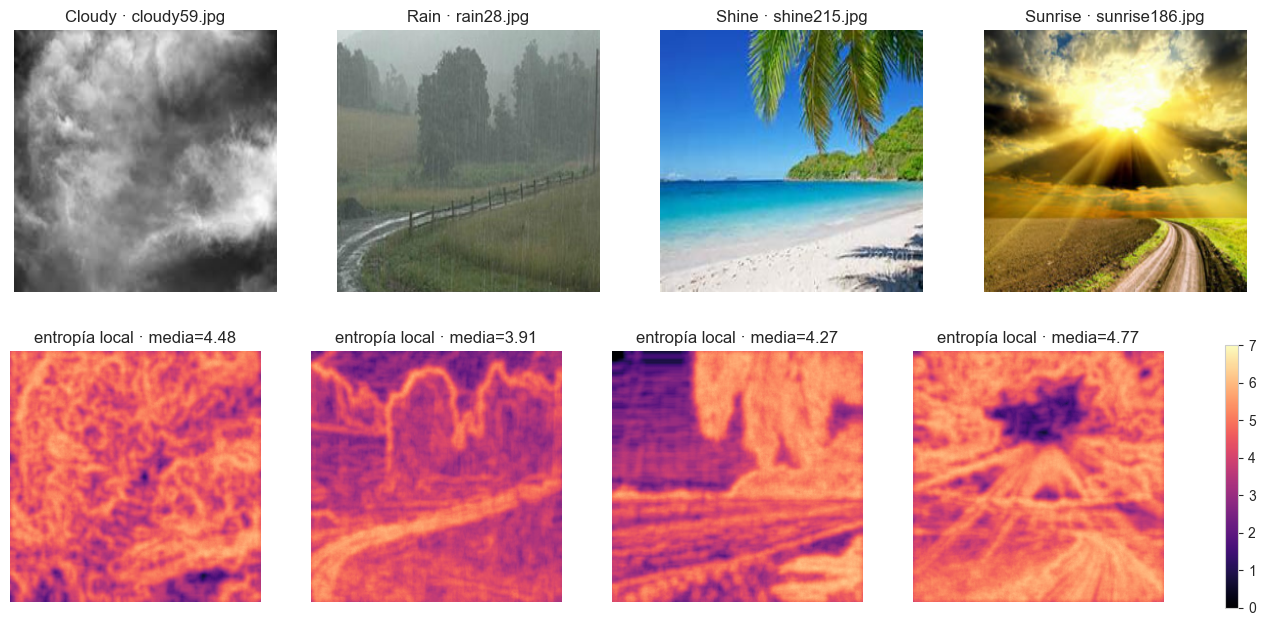

In [19]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for k, clase in enumerate(CLASES):
    i = rng.choice(np.where(y == clase)[0])
    im = cargar(ok.ruta[i], 256)
    gris = util.img_as_ubyte(color.rgb2gray(im))
    ent = rank_entropy(gris, morphology.disk(5))
    axes[0, k].imshow(im); axes[0, k].set_title(f'{clase} · {ok.archivo[i]}')
    m = axes[1, k].imshow(ent, cmap='magma', vmin=0, vmax=7)
    axes[1, k].set_title(f'entropía local · media={ent.mean():.2f}')
    for a in axes[:, k]: a.axis('off')
plt.colorbar(m, ax=axes[1, :], fraction=0.02); plt.show()

**Qué vemos.** En los mapas se ve muy bien qué mide la entropía local: es baja en las zonas lisas (el cielo despejado de Shine o el sol de Sunrise, que aparece como una mancha oscura) y alta en las zonas con textura, como las nubes, la vegetación, los caminos o los trazos de la lluvia.

Pero hay que tener cuidado con sacar conclusiones de ejemplos sueltos. Aquí, la foto de lluvia (`rain28`, un paisaje con niebla) tiene menos entropía (3,91) que la de Shine (4,27), porque la niebla suaviza la imagen. La entropía separa las clases en promedio, pero individualmente hay mucho solapamiento, así que no puede usarse sola: tiene que ir acompañada del color.

100%|██████████| 200/200 [00:08<00:00, 24.38it/s]


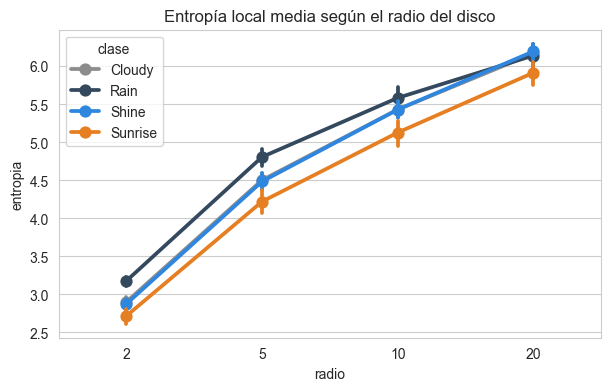

In [20]:
radios = [2, 5, 10, 20]
sub = np.concatenate([rng.choice(np.where(y == c)[0], 50, replace=False) for c in CLASES])
filas = []
for i in tqdm(sub):
    gris = util.img_as_ubyte(color.rgb2gray(X[i]))
    for r in radios:
        filas.append([y[i], r, rank_entropy(gris, morphology.disk(r)).mean()])
esc = pd.DataFrame(filas, columns=['clase', 'radio', 'entropia'])

plt.figure(figsize=(7, 4))
sns.pointplot(data=esc, x='radio', y='entropia', hue='clase', palette=COLORES, hue_order=CLASES)
plt.title('Entropía local media según el radio del disco'); plt.show()

**Qué vemos.** Como era de esperar, la entropía aumenta con el tamaño de la ventana en todas las clases: cuanto más grande es el vecindario, más niveles de gris distintos recoge.

Lo importante es cómo cambian las diferencias entre clases. Con radios de 2 a 10 píxeles, **Rain es siempre la clase con más entropía** y Sunrise la que menos, mientras que Cloudy y Shine van prácticamente juntas. Pero con un radio de 20 las diferencias desaparecen (todas rondan 6,0-6,2), porque la ventana es tan grande que acaba mezclando cielo y suelo en todas las imágenes.

Es decir, la textura que delata la lluvia es una textura **fina**. Para imágenes de 128 píxeles, un radio pequeño o mediano (entre 2 y 5) es el que mejor discrimina. Si cambiamos la resolución, el radio debería cambiar en proporción.

## 12. Poder discriminativo de cada característica
- **Kruskal-Wallis** (ANOVA no paramétrico) + tamaño del efecto η²: ¿difiere la característica entre las 4 clases?
- **Información mutua**: cuánta información aporta sobre la clase (capta relaciones no lineales).
- **AUC univariante por pares**: qué característica separa mejor cada par concreto de clases.

,H,p,eta2,MI
feature,,,,
colorfulness,775.563,8.631e-168,0.689,0.573
b_media,665.557,6.172e-144,0.591,0.568
b_var,703.616,3.451e-152,0.625,0.553
p_calido,783.318,1.795e-169,0.696,0.552
S_media,701.654,9.191e-152,0.623,0.532
B_media,728.299,1.533e-157,0.647,0.526
H_media_circ,289.318,0.000e+00,0.255,0.520
a_media,618.479,9.935e-134,0.549,0.502
a_var,677.060,1.978e-146,0.601,0.436


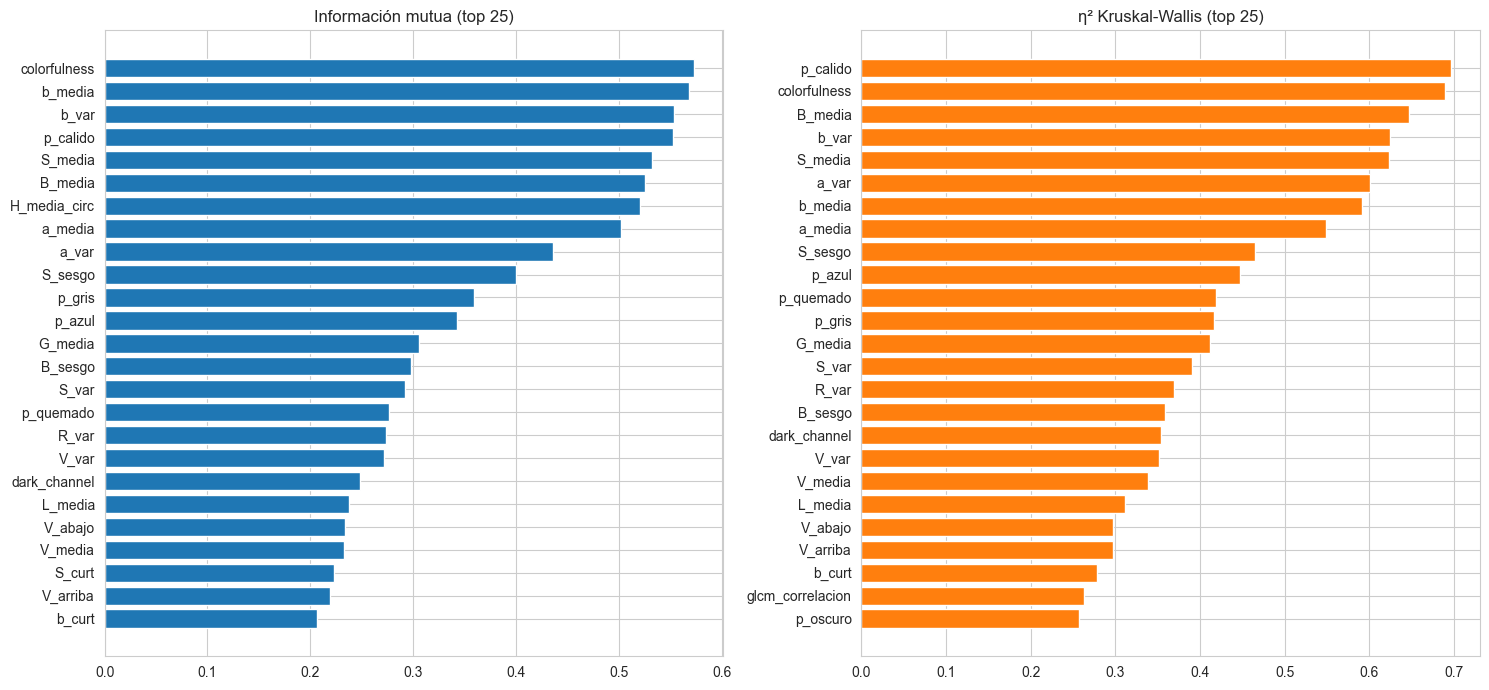

In [21]:
from sklearn.feature_selection import mutual_info_classif

n, k = len(feats), len(CLASES)
res = []
for c in cols:
    Hk, p = stats.kruskal(*[feats.loc[feats.clase == cl, c] for cl in CLASES])
    res.append([c, Hk, p, (Hk - k + 1) / (n - k)])
rank = pd.DataFrame(res, columns=['feature', 'H', 'p', 'eta2']).set_index('feature')
rank['MI'] = mutual_info_classif(feats[cols], feats.clase, random_state=SEED)
rank = rank.sort_values('MI', ascending=False)
display(rank.head(25))

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
top = rank.head(25)
axes[0].barh(top.index[::-1], top.MI[::-1]); axes[0].set_title('Información mutua (top 25)')
top2 = rank.sort_values('eta2', ascending=False).head(25)
axes[1].barh(top2.index[::-1], top2.eta2[::-1], color='tab:orange'); axes[1].set_title('η² Kruskal-Wallis (top 25)')
plt.tight_layout(); plt.show()

**Qué vemos.** Todas las características del top 25 son estadísticamente significativas (los p-valores que aparecen como 0,000 no son ceros reales, sino números tan pequeños que el ordenador no puede representarlos).

Según la información mutua, las más informativas son **todas de color**: la colorfulness (0,573), la media de b\* (0,568), la varianza de b\* (0,553), la proporción de píxeles cálidos (0,552), la saturación media (0,532) y la media del canal azul (0,526).

Hay un caso curioso: la **media circular del tono** tiene una información mutua alta (0,52) pero un η² bastante bajo (0,26). La explicación está en cómo funciona cada medida. Kruskal-Wallis trabaja con rangos, es decir, asume que los valores tienen un orden. Pero el tono es circular: el naranja (en torno a 0,05) y el azul (en torno a 0,6) quedan en extremos, y las fotos casi grises caen en cualquier sitio. La información mutua no necesita esa relación ordenada y por eso la detecta.

Las características de entropía y textura no aparecen en este top 25. Eso no significa que no sirvan: compiten contra el color en las cuatro clases a la vez, y el color gana porque separa casi todo. Su utilidad aparece cuando miramos parejas concretas, que es lo que hacemos a continuación.

Mejores 3 características por par (AUC univariante):
  Cloudy vs Rain       → glcm_correlacion (0.87) · glcm_homogeneidad (0.85) · entloc_std (0.79)
  Cloudy vs Shine      → colorfulness (0.95) · V_media (0.90) · S_media (0.90)
  Cloudy vs Sunrise    → p_calido (0.99) · a_var (0.99) · colorfulness (0.98)
  Rain vs Shine        → colorfulness (0.98) · b_var (0.96) · S_var (0.95)
  Rain vs Sunrise      → colorfulness (0.99) · b_var (0.99) · p_calido (0.99)
  Shine vs Sunrise     → p_calido (0.99) · B_media (0.99) · p_azul (0.97)


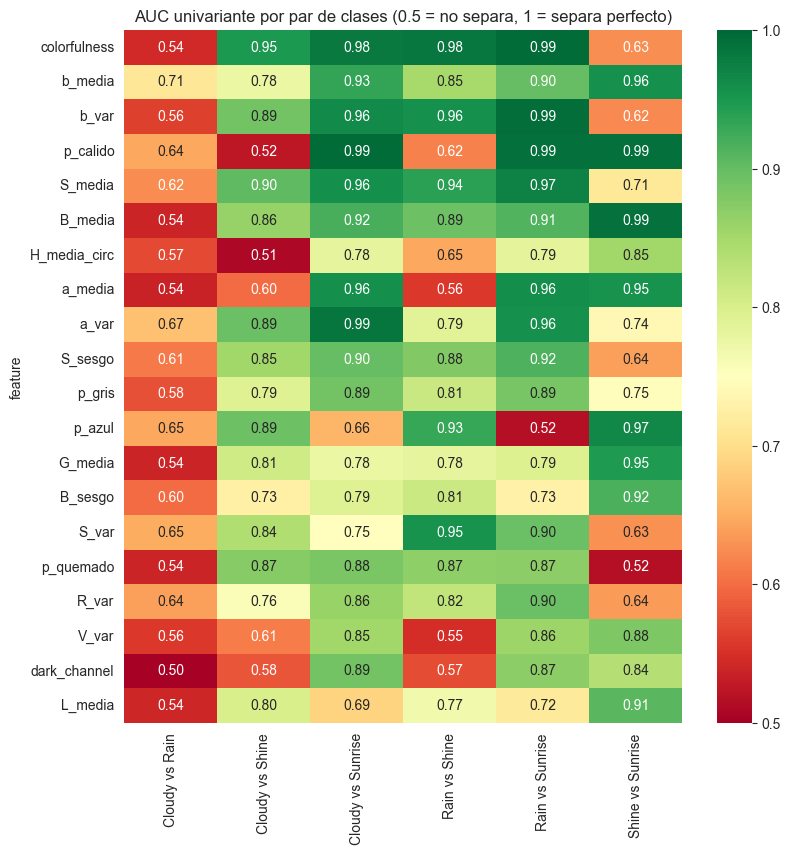

In [22]:
from sklearn.metrics import roc_auc_score

auc_sep = {}
for a, b in combinations(CLASES, 2):
    sub_ = feats[feats.clase.isin([a, b])]
    yy = (sub_.clase == b).astype(int)
    auc_sep[f'{a} vs {b}'] = {c: max(roc_auc_score(yy, sub_[c]), 1 - roc_auc_score(yy, sub_[c])) for c in cols}
auc_sep = pd.DataFrame(auc_sep)

print('Mejores 3 características por par (AUC univariante):')
for par in auc_sep.columns:
    s = auc_sep[par].sort_values(ascending=False).head(3)
    print(f'  {par:20s} → ' + ' · '.join(f'{i} ({v:.2f})' for i, v in s.items()))

top_feats = rank.head(20).index
plt.figure(figsize=(9, 9))
sns.heatmap(auc_sep.loc[top_feats], annot=True, fmt='.2f', cmap='RdYlGn', vmin=.5, vmax=1)
plt.title('AUC univariante por par de clases (0.5 = no separa, 1 = separa perfecto)'); plt.show()

**Qué vemos.** Esta celda es seguramente la conclusión más importante de todo el análisis.

En cinco de las seis parejas de clases basta **una sola característica de color** para separarlas casi perfectamente, con AUC entre 0,95 y 0,99. Por ejemplo, la proporción de píxeles cálidos separa Cloudy de Sunrise (0,99) y Shine de Sunrise (0,99), y la colorfulness separa Rain de Shine (0,98).

La excepción es **Cloudy contra Rain**. Es la única pareja en la que las mejores características son de **textura**: la correlación GLCM (0,87), la homogeneidad GLCM (0,85) y la desviación típica de la entropía local (0,79). Ninguna característica de color llega a esos valores para esta pareja.

Esto valida el planteamiento de la diapositiva: las características espectrales (HSV y Lab) resuelven la mayor parte del problema, y la entropía y la textura son necesarias para la parte que el color no resuelve. También nos hace esperar que la confusión entre Cloudy y Rain sea la más frecuente del clasificador (aunque, como veremos al final, no es exactamente así).

## 13. Redundancia entre características

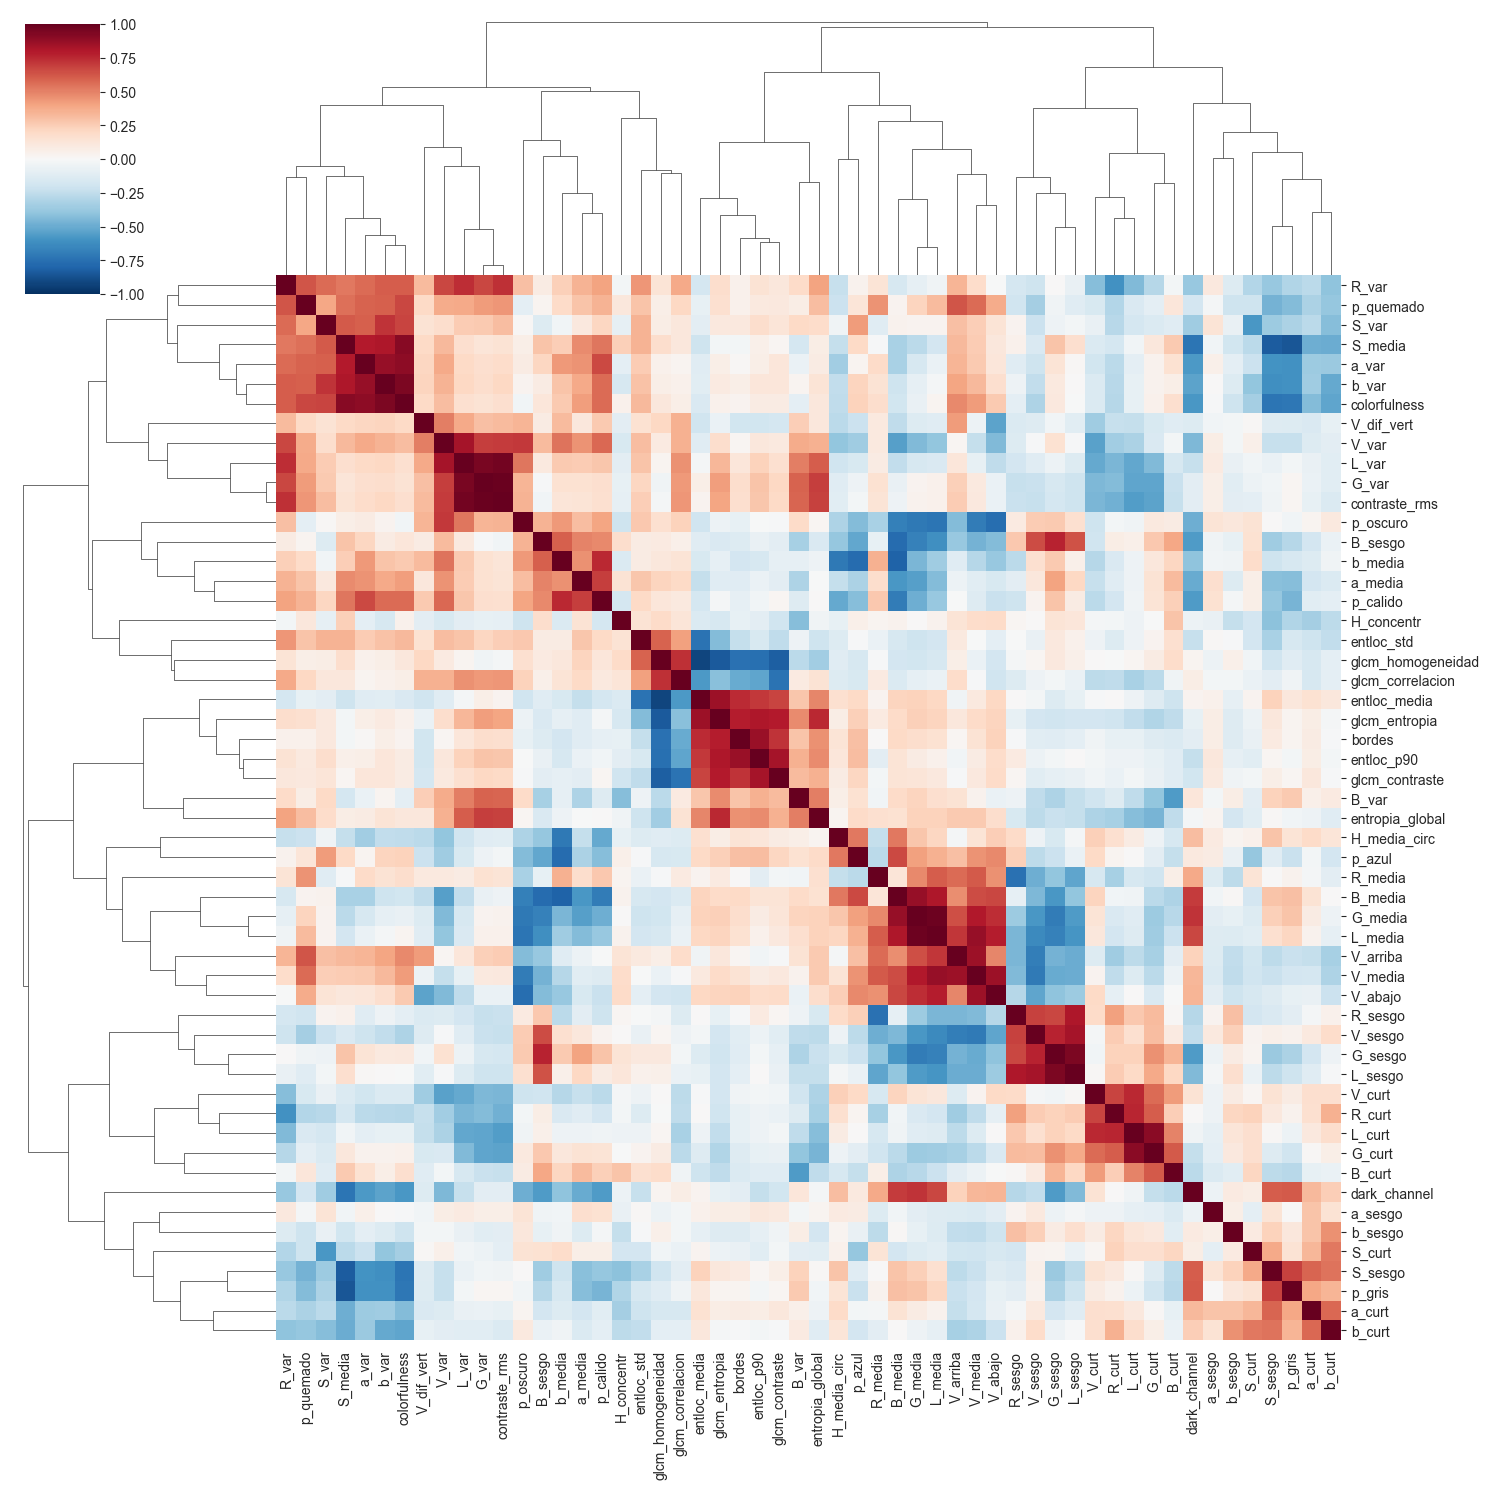

Pares con |ρ| > 0.95: 4


,,rho
G_var,contraste_rms,0.988
G_media,L_media,0.982
L_var,contraste_rms,0.962
G_var,L_var,0.952


In [23]:
corr = feats[cols].corr(method='spearman')
sns.clustermap(corr, cmap='RdBu_r', vmin=-1, vmax=1, figsize=(15, 15), xticklabels=True, yticklabels=True)
plt.show()

red = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
red = red[red.abs() > 0.95].sort_values(key=abs, ascending=False)
print(f'Pares con |ρ| > 0.95: {len(red)}')
display(red.to_frame('rho').head(30))

**Qué vemos.** El mapa de correlaciones agrupa las características en bloques que tienen sentido: las medias de brillo (R, G, B, V y L) por un lado, las varianzas y el contraste por otro, y un bloque de «color cálido» con a\*, b\*, los píxeles cálidos y la saturación.

Aun así, la redundancia es baja. Solo hay **cuatro parejas con una correlación por encima de 0,95**: la varianza de G con el contraste RMS (0,988), la media de G con la media de L\* (0,982), la varianza de L\* con el contraste (0,962) y la varianza de G con la de L\* (0,952). Todas tienen la misma explicación: tanto la conversión a gris como la luminancia L\* dependen sobre todo del canal verde (en `rgb2gray` pesa un 0,72).

Podríamos quitar el contraste RMS y la media de L\* sin perder información. El resto de características aporta información distinta.

## 14. Proyección 2D del espacio de características

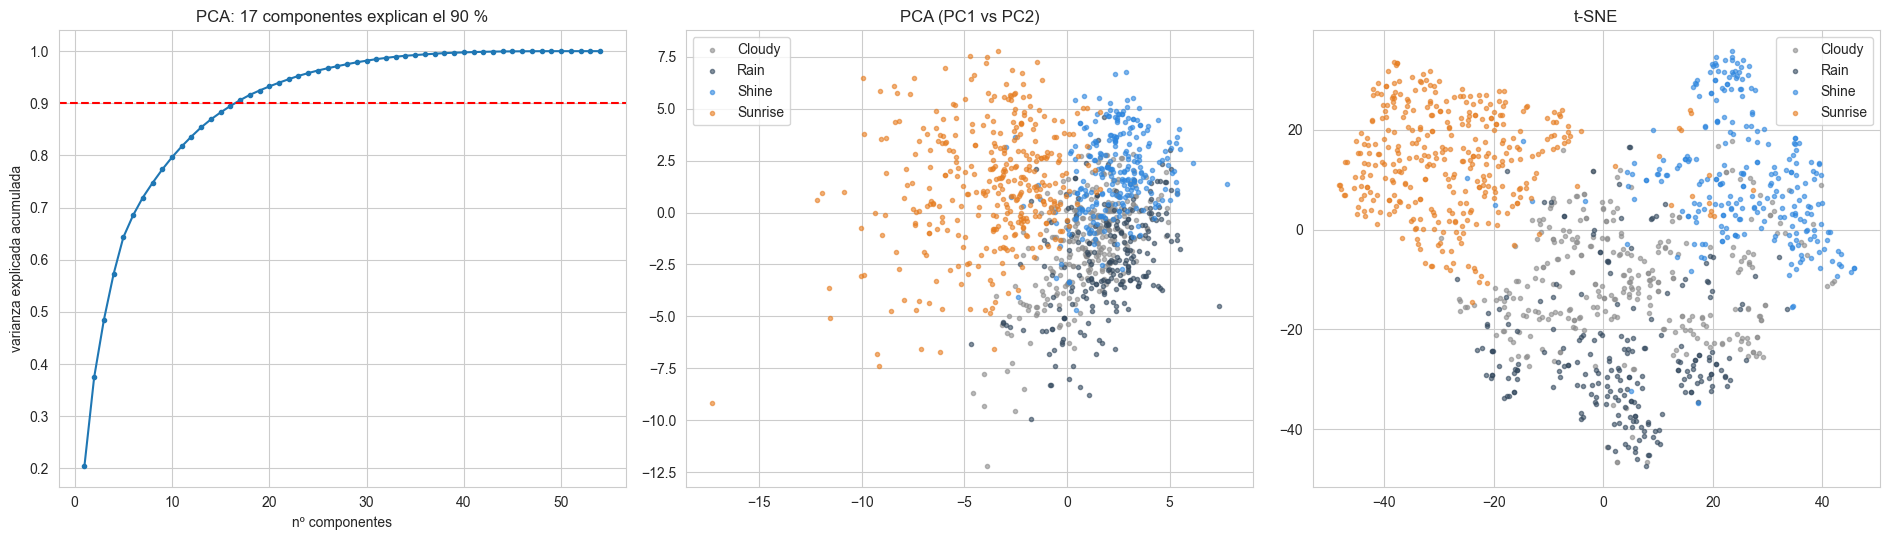

PC1 — mayores cargas: B_media, G_media, L_media, B_sesgo, dark_channel, p_calido
PC2 — mayores cargas: V_arriba, R_var, V_media, colorfulness, p_quemado, V_sesgo


In [24]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

Z = StandardScaler().fit_transform(feats[cols])
pca = PCA().fit(Z)
P2 = pca.transform(Z)[:, :2]
T2 = TSNE(2, perplexity=30, init='pca', random_state=SEED).fit_transform(Z)

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
cum = np.cumsum(pca.explained_variance_ratio_)
axes[0].plot(np.arange(1, len(cum) + 1), cum, marker='.'); axes[0].axhline(.9, ls='--', c='r')
axes[0].set_xlabel('nº componentes'); axes[0].set_ylabel('varianza explicada acumulada')
axes[0].set_title(f'PCA: {np.argmax(cum >= .9) + 1} componentes explican el 90 %')
for ax, E, t in [(axes[1], P2, 'PCA (PC1 vs PC2)'), (axes[2], T2, 't-SNE')]:
    for clase in CLASES:
        m = y == clase
        ax.scatter(E[m, 0], E[m, 1], s=9, alpha=.6, c=COLORES[clase], label=clase)
    ax.set_title(t); ax.legend()
plt.tight_layout(); plt.show()

carg = pd.DataFrame(pca.components_[:2].T, index=cols, columns=['PC1', 'PC2'])
for pc in ['PC1', 'PC2']:
    print(f'{pc} — mayores cargas:', ', '.join(carg[pc].abs().sort_values(ascending=False).head(6).index))

**Qué vemos.** Hacen falta **17 componentes principales para explicar el 90 %** de la varianza, y la primera sola explica alrededor del 20 %. La información está repartida entre muchas características, lo cual encaja con la poca redundancia que vimos antes.

Las dos primeras componentes se pueden interpretar. La **PC1** va del «azul y brillante» al «cálido y oscuro» (el canal azul, el verde, L\*, el dark channel y los píxeles cálidos) y es la que aparta a Sunrise hacia la izquierda. La **PC2** recoge el brillo de la parte superior y el colorido, y separa Shine (arriba) de Rain (abajo).

En la proyección lineal, Sunrise y Shine se separan bastante, pero **Cloudy y Rain se pisan casi por completo**. El t-SNE, que no es lineal, lo deja más claro todavía: Sunrise forma un grupo compacto a la izquierda, Shine otro arriba a la derecha, y en el centro y la parte de abajo quedan Cloudy y Rain mezcladas, con Rain algo más concentrada abajo. Algunas fotos de Cloudy se cuelan cerca de Shine; son las de nubes blancas sobre cielo azul.

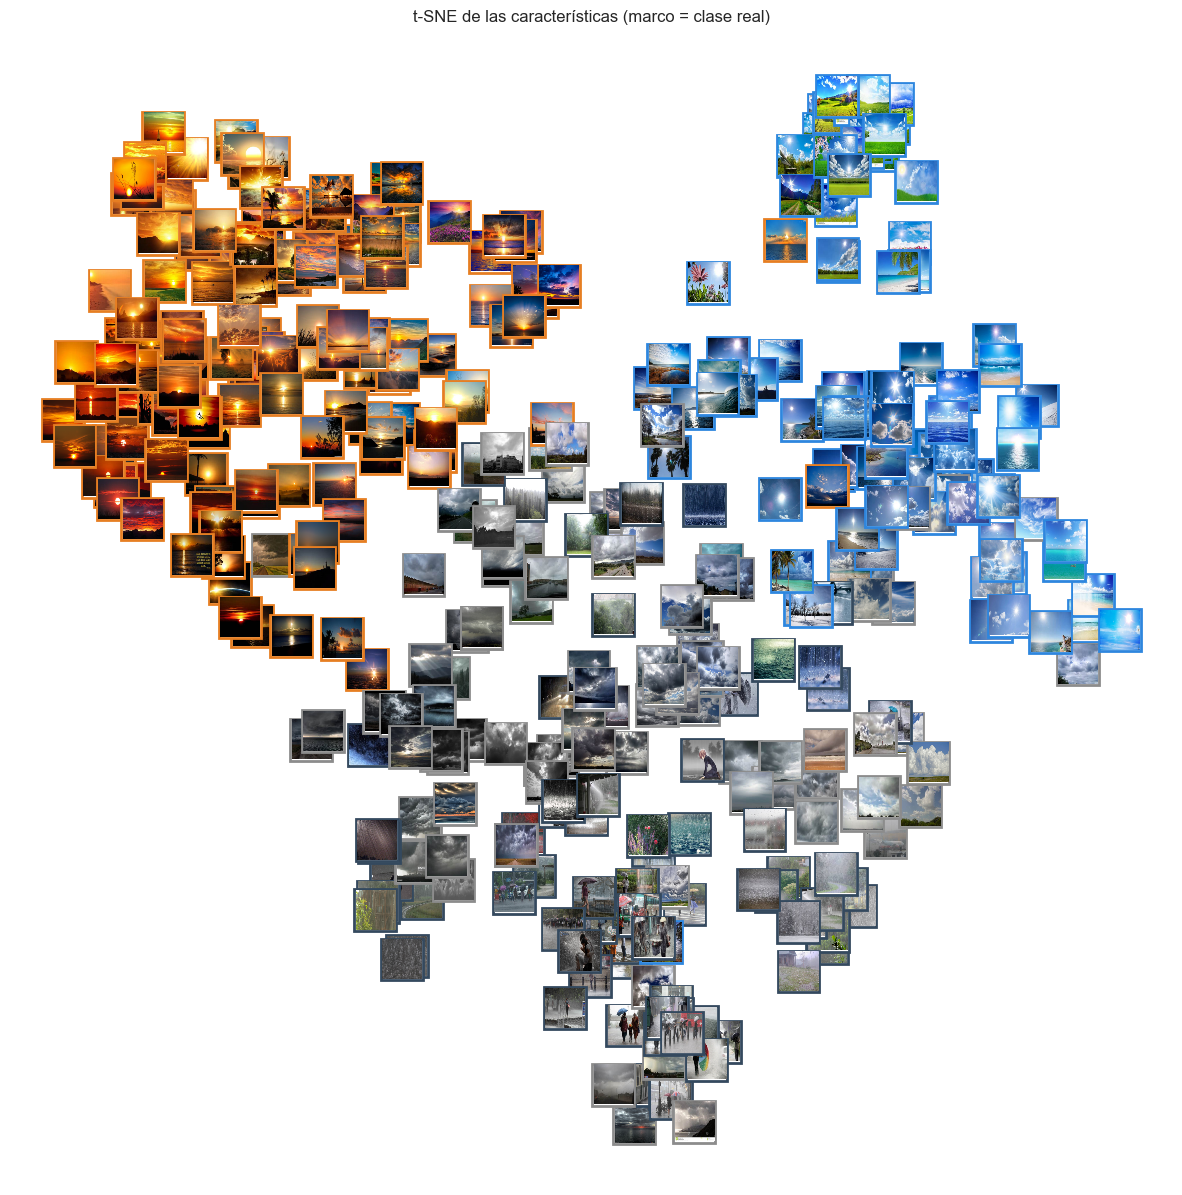

In [25]:
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

fig, ax = plt.subplots(figsize=(15, 15))
ax.scatter(T2[:, 0], T2[:, 1], s=0)
for i in rng.choice(len(X), 400, replace=False):
    ab = AnnotationBbox(OffsetImage(X[i], zoom=0.22), T2[i], pad=0.1,
                        bboxprops=dict(edgecolor=COLORES[y[i]], lw=2))
    ax.add_artist(ab)
ax.set_title('t-SNE de las características (marco = clase real)'); ax.axis('off'); plt.show()

**Qué vemos.** Poner las miniaturas encima del t-SNE permite ver qué ha aprendido realmente el espacio de características.

A la izquierda están los amaneceres y atardeceres, ordenados más o menos de los más rojos a los más dorados. Arriba a la derecha hay praderas verdes con cielo azul, y más abajo, soles blancos, playas y mar. En el centro aparecen los cielos nublados grises, que hacen de transición, y en la parte inferior las escenas urbanas de lluvia, con gente y paraguas, junto con las fotos en blanco y negro.

También se ven algunos casos curiosos, como amaneceres con tonos fríos que acaban en la zona de Shine. Esto revela una limitación de las características clásicas: agrupan las imágenes **por cómo se ven**, no por el fenómeno meteorológico que muestran. Es justo lo que esperamos que CLIP haga mejor.

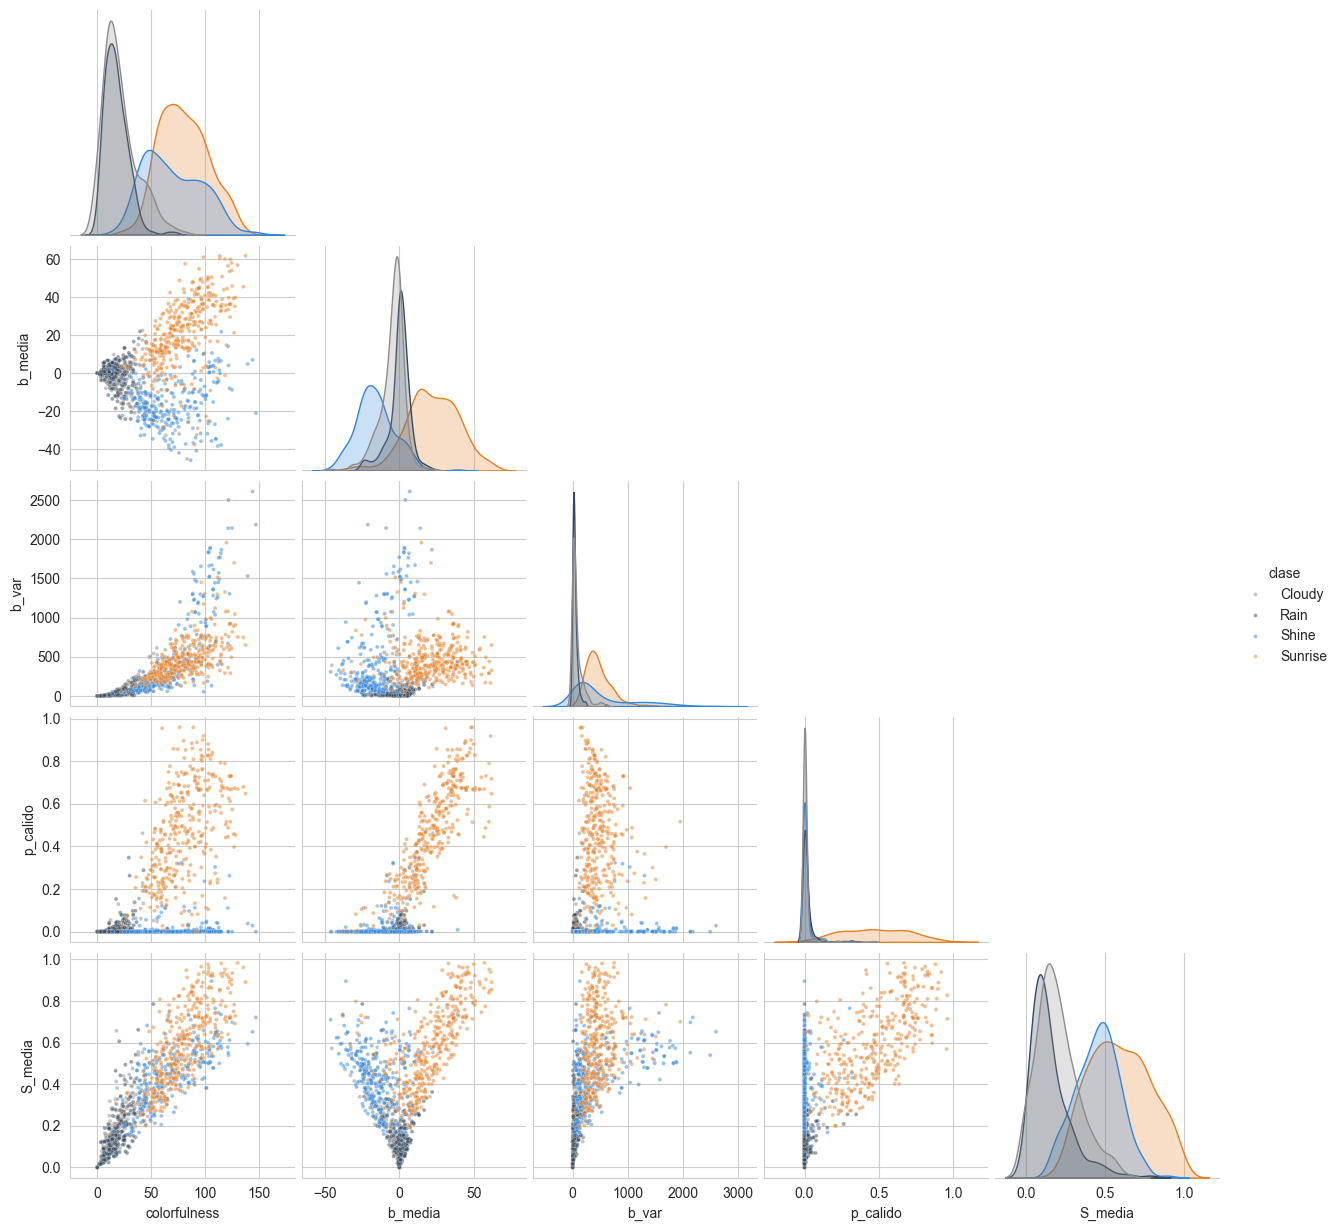

In [26]:
top5 = list(rank.head(5).index)
sns.pairplot(feats[top5 + ['clase']], hue='clase', palette=COLORES, hue_order=CLASES,
             corner=True, plot_kws=dict(s=8, alpha=.5))
plt.show()

**Qué vemos.** El gráfico de colorfulness frente a b\* es casi un clasificador por sí solo. Cloudy y Rain se quedan en el origen (poco color y b\* cercano a cero), Shine se va hacia abajo a la derecha (b\* negativo) y Sunrise hacia arriba a la derecha (b\* positivo).

La proporción de píxeles cálidos vale prácticamente cero en todo lo que no es Sunrise, así que funciona casi como un detector de esa clase. Y la combinación de saturación y b\* dibuja una especie de «V»: Shine y Sunrise ocupan las dos ramas (mucha saturación, b\* de signos opuestos) y Cloudy y Rain se quedan en el vértice.

En todas las combinaciones se repite lo mismo: **Cloudy y Rain se solapan**. Con las cinco mejores características de color no hay manera de separarlas, lo que vuelve a confirmar que la textura es imprescindible.

## 15. Imágenes atípicas y posibles errores de etiqueta
Para cada imagen miramos sus 10 vecinos más cercanos en el espacio de características. Si casi todos son de otra clase, puede ser una imagen ambigua o mal etiquetada.

Pureza media de vecindario por clase:


clase
Cloudy     0.756
Rain       0.676
Shine      0.825
Sunrise    0.934
Name: pureza_vecinos, dtype: float64

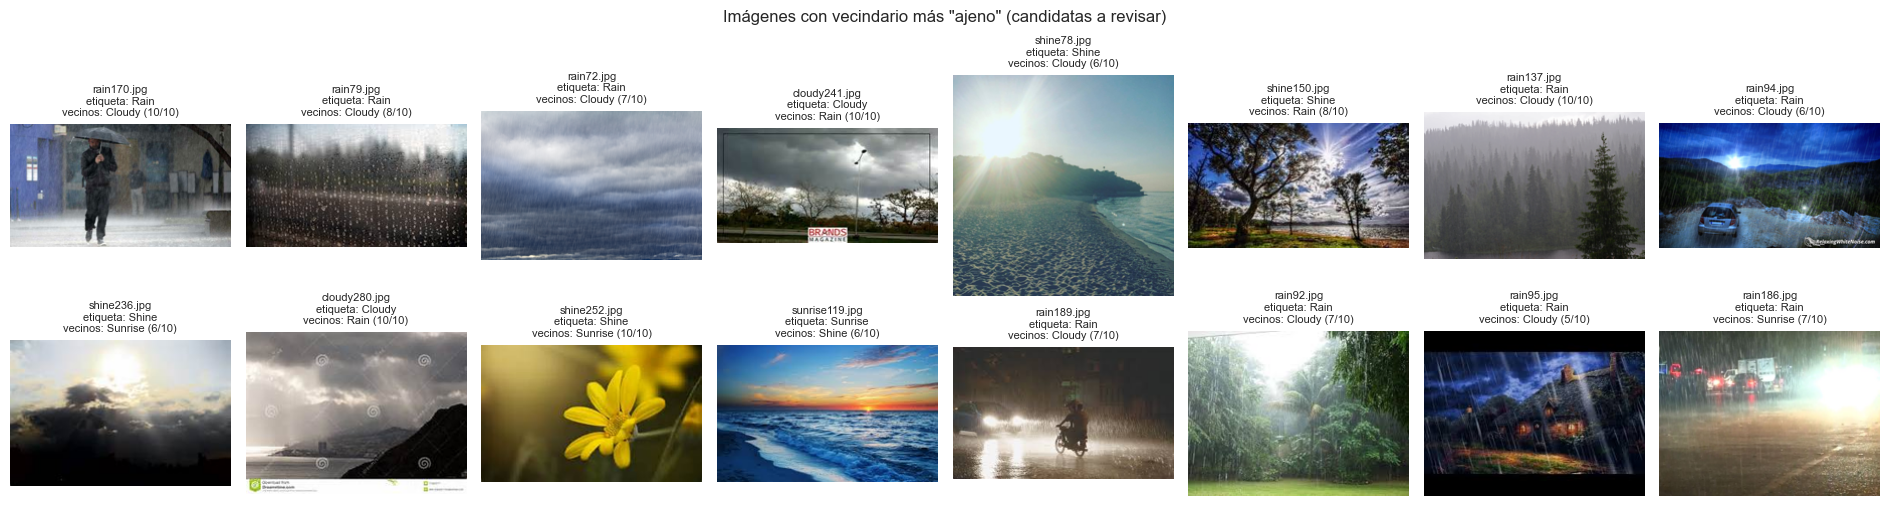

In [27]:
from sklearn.neighbors import NearestNeighbors

_, idx = NearestNeighbors(n_neighbors=11).fit(Z).kneighbors(Z)
vecinos = y[idx[:, 1:]]
pureza = (vecinos == y[:, None]).mean(1)
ok['pureza_vecinos'] = pureza
print('Pureza media de vecindario por clase:')
display(ok.groupby('clase').pureza_vecinos.mean())

sosp = np.argsort(pureza)[:16]
fig, axes = plt.subplots(2, 8, figsize=(19, 5.5))
for ax, i in zip(axes.ravel(), sosp):
    otra, n_ = Counter(vecinos[i]).most_common(1)[0]
    ax.imshow(vista(ok.ruta[i])); ax.axis('off')
    ax.set_title(f'{ok.archivo[i]}\netiqueta: {y[i]}\nvecinos: {otra} ({n_}/10)', fontsize=8)
plt.suptitle('Imágenes con vecindario más "ajeno" (candidatas a revisar)'); plt.tight_layout(); plt.show()

**Qué vemos.** Para cada imagen miramos cuántos de sus diez vecinos más cercanos son de su misma clase. De media, Sunrise es la clase más «compacta» (0,93), seguida de Shine (0,83), Cloudy (0,76) y, por último, **Rain (0,68)**. Es decir, un tercio de los vecinos de una foto de lluvia son de otra clase, casi siempre de Cloudy.

Al revisar las 16 imágenes más atípicas, encontramos tres tipos de casos:

- **Lluvia sin rastro de color**, que acaba rodeada de fotos nubladas: `rain170`, `rain79`, `rain72`, `rain137`, `rain92` o `rain189`. La etiqueta es correcta; lo que pasa es que la lluvia se nota en detalles finos que las características de color no recogen.
- **Imágenes ambiguas o discutibles.** `shine236` muestra el sol entre nubes oscuras (¿es soleado o nublado?), `shine252` es una flor amarilla en primer plano que poco tiene que ver con el tiempo, `sunrise119` es un atardecer con muchísimo mar azul y `shine150` tiene tanto árbol que la estructura domina sobre el cielo.
- **Marcas de agua y bordes.** `cloudy241` lleva el logo «BRANDS MAGAZINE» y un marco negro, y `cloudy280` tiene la marca de agua de Dreamstime. Son elementos ajenos a la escena que contaminan las características globales.

No hemos encontrado errores de etiquetado evidentes, pero sí algo de ruido y casos que hasta a una persona le costaría clasificar. Para limpiar el dataset se podría eliminar alguna imagen como `shine252` y recortar los bordes de las que tienen marco.

## 16. Separabilidad rápida (avance, no es el modelo final)
Comprobación rápida de cuánto separan los grupos de características de la diapositiva. Usamos validación cruzada **por grupos de duplicados** para que no haya fuga entre folds.

,n_feats,exactitud,f1_macro
Momentos RGB,12.0,0.782,0.767
Momentos HSV + Lab,25.0,0.829,0.817
Entropía / textura,10.0,0.608,0.614
HSV + Lab + entropía,29.0,0.876,0.868
Todas,54.0,0.922,0.918


              precision    recall  f1-score   support

      Cloudy      0.897     0.870     0.883       300
        Rain      0.909     0.926     0.917       215
       Shine      0.875     0.909     0.891       253
     Sunrise      0.986     0.972     0.979       357

    accuracy                          0.922      1125
   macro avg      0.916     0.919     0.918      1125
weighted avg      0.922     0.922     0.922      1125



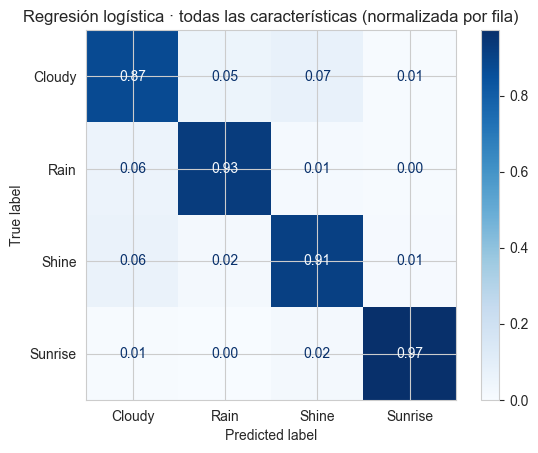

In [28]:
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay, classification_report

grupos_feats = {
    'Momentos RGB': [c for c in cols if c.split('_')[0] in {'R', 'G', 'B'}],
    'Momentos HSV + Lab': [c for c in cols if c.split('_')[0] in {'H', 'S', 'V', 'L', 'a', 'b'}],
    'Entropía / textura': [c for c in cols if c.startswith(('entloc', 'entropia', 'glcm', 'bordes', 'contraste'))],
    'HSV + Lab + entropía': [c for c in cols if c.split('_')[0] in {'H', 'S', 'V', 'L', 'a', 'b'}
                             or c.startswith(('entloc', 'entropia'))],
    'Todas': list(cols),
}
cvg = StratifiedGroupKFold(5, shuffle=True, random_state=SEED)
modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight='balanced'))

resumen = {}
for nombre, cs in grupos_feats.items():
    pred = cross_val_predict(modelo, feats[cs], y, cv=cvg, groups=ok.grupo_dup)
    resumen[nombre] = dict(n_feats=len(cs), exactitud=accuracy_score(y, pred), f1_macro=f1_score(y, pred, average='macro'))
    if nombre == 'Todas':
        pred_todas = pred
display(pd.DataFrame(resumen).T)

print(classification_report(y, pred_todas, digits=3))
ConfusionMatrixDisplay.from_predictions(y, pred_todas, labels=CLASES, normalize='true', cmap='Blues', values_format='.2f')
plt.title('Regresión logística · todas las características (normalizada por fila)'); plt.show()

**Qué vemos.** Antes de pasar al modelo de verdad, hemos querido comprobar hasta qué punto son separables las clases con estas características, usando algo tan sencillo como una regresión logística y una validación cruzada que respeta los grupos de duplicados.

| Características | nº | Exactitud | F1-macro |
|---|---|---|---|
| Momentos RGB | 12 | 0,782 | 0,767 |
| Momentos HSV + Lab | 25 | 0,829 | 0,817 |
| Entropía / textura | 10 | 0,608 | 0,614 |
| HSV + Lab + entropía | 29 | 0,876 | 0,868 |
| Todas | 54 | **0,922** | **0,918** |

Los resultados confirman lo que venía apuntando el análisis. **HSV y Lab ganan a RGB por casi cinco puntos**, igual que veíamos en los histogramas. La entropía y la textura por sí solas se quedan en un 61 %, que es poco pero bastante por encima del 31,7 % del azar. Lo interesante es que, **sumadas al color, aportan otros cinco puntos** (de 0,829 a 0,876), porque cubren justo lo que el color no resuelve. Con todas las características juntas llegamos al **92,2 %**, lo que demuestra que el problema es bastante abordable con descriptores clásicos.

Por clases, Sunrise es claramente la más fácil (F1 de 0,979), seguida de Rain (0,917), Shine (0,891) y Cloudy (0,883). La matriz de confusión deja ver que **Cloudy está en el centro de casi todos los errores**: un 7 % de sus imágenes se confunden con Shine y un 5 % con Rain, y en sentido contrario, un 6 % de Shine y un 6 % de Rain acaban clasificadas como Cloudy. Tiene sentido: un día nublado con claros se parece a uno soleado, y uno nublado y oscuro, a uno de lluvia. Rain sale mejor parada de lo que esperábamos (93 % de recall) porque el modelo combina color y textura, y eso compensa la debilidad que veíamos al analizar las características una a una.

Como la validación agrupa los duplicados, podemos estar tranquilos de que estos números no están inflados por imágenes repetidas entre entrenamiento y test.

## 17. Conclusiones del análisis exploratorio

Después de revisar el dataset a fondo, nos quedamos con estas ideas:

1. **El dataset está completo pero no es homogéneo.** No hay archivos corruptos, pero ocho imágenes tienen una extensión que no corresponde con su formato real (seis PNG y dos GIF) y cinco no están en RGB. Lo resolvemos cargando con PIL y convirtiendo siempre a RGB.
2. **Las clases están razonablemente equilibradas.** Sunrise tiene un 31,7 % de las imágenes y Rain un 19,1 %. Usaremos F1-macro y pesos de clase para que Rain no salga perjudicada.
3. **Hay un sesgo de origen moderado.** Las fotos de lluvia son más grandes y pesadas, y solo con los metadatos se acierta un 41 % (frente al 31,7 % del azar). Por eso redimensionamos todo y no usamos el tamaño como característica.
4. **Las 71 fotos en blanco y negro están todas en Cloudy y Rain.** Es un sesgo a vigilar cuando probemos el modelo con imágenes nuevas.
5. **Hay duplicados, pero no etiquetas contradictorias.** Combinando estructura y color encontramos 121 pares de casi-duplicados, todos dentro de la misma clase (sobre todo en Cloudy). Las 1125 imágenes se reducen a 1015 grupos, y la validación los respeta para evitar fugas de datos.
6. **El color resuelve casi todo.** El tono (tratado como circular y ponderado por la saturación), b\*, a\*, la saturación y la colorfulness separan Shine y Sunrise del resto con AUC entre 0,95 y 0,99.
7. **La entropía y la textura son imprescindibles para separar Cloudy de Rain** (AUC de 0,87 con la GLCM). La lluvia tiene más entropía local a escala fina (radios de 2 a 10 píxeles).
8. **La posición vertical importa.** Sunrise tiene un fuerte contraste entre arriba y abajo y Rain ninguno, así que vale la pena añadir características por regiones.
9. **Con descriptores clásicos ya llegamos al 92,2 %** usando una regresión logística. Cloudy es la clase que más se confunde, tanto con Shine (días con claros) como con Rain (días oscuros).
10. **Siguientes pasos:** entrenar el clasificador final de cuatro clases, probar CLIP zero-shot (incluyendo clases nuevas como niebla y nieve) y hacer el reto de las diez fotos con el móvil, prestando atención a lo distintas que serán de las del dataset en resolución y tipo de cámara.